In [1]:
import os

data_path = "../data/"

for root, dirs, files in os.walk(data_path):
    for file in files:
        print(file)

campaign_desc.csv
campaign_table.csv
causal_data.csv
coupon.csv
coupon_redempt.csv
hh_demographic.csv
product.csv
transaction_data.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os
import warnings

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

In [3]:
data_path = "../data/"

transaction = pd.read_csv(data_path + "transaction_data.csv")
product = pd.read_csv(data_path + "product.csv")
demographic = pd.read_csv(data_path + "hh_demographic.csv")

campaign_desc = pd.read_csv(data_path + "campaign_desc.csv")
campaign_table = pd.read_csv(data_path + "campaign_table.csv")

coupon = pd.read_csv(data_path + "coupon.csv")
coupon_redempt = pd.read_csv(data_path + "coupon_redempt.csv")
causal = pd.read_csv(data_path + "causal_data.csv")

In [4]:
datasets = {
    "Transaction": transaction,
    "Product": product,
    "Demographic": demographic,
    "Campaign Description": campaign_desc,
    "Campaign Table": campaign_table,
    "Coupon": coupon,
    "Coupon Redemption": coupon_redempt,
    "Causal": causal
}

for name, data in datasets.items():
    print(f"{name}: {data.shape}")

Transaction: (2595732, 12)
Product: (92353, 7)
Demographic: (801, 8)
Campaign Description: (30, 4)
Campaign Table: (7208, 3)
Coupon: (124548, 3)
Coupon Redemption: (2318, 4)
Causal: (36786524, 5)


In [5]:
transaction.head()

,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC
0,2375,26984851472,1,1004906,1,1.39,364,-0.60,1631,1,0.0,0.0
1,2375,26984851472,1,1033142,1,0.82,364,0.00,1631,1,0.0,0.0
2,2375,26984851472,1,1036325,1,0.99,364,-0.30,1631,1,0.0,0.0
3,2375,26984851472,1,1082185,1,1.21,364,0.00,1631,1,0.0,0.0
4,2375,26984851472,1,8160430,1,1.50,364,-0.39,1631,1,0.0,0.0


In [6]:
transaction.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2595732 entries, 0 to 2595731
Data columns (total 12 columns):
 #   Column             Dtype  
---  ------             -----  
 0   household_key      int64  
 1   BASKET_ID          int64  
 2   DAY                int64  
 3   PRODUCT_ID         int64  
 4   QUANTITY           int64  
 5   SALES_VALUE        float64
 6   STORE_ID           int64  
 7   RETAIL_DISC        float64
 8   TRANS_TIME         int64  
 9   WEEK_NO            int64  
 10  COUPON_DISC        float64
 11  COUPON_MATCH_DISC  float64
dtypes: float64(4), int64(8)
memory usage: 237.6 MB


In [7]:
transaction.describe().T

,count,mean,std,min,25%,50%,75%,max
household_key,2595732.0,1.271953e+03,7.260660e+02,1.000000e+00,6.560000e+02,1.272000e+03,1.913000e+03,2.500000e+03
BASKET_ID,2595732.0,3.402620e+10,4.711649e+09,2.698485e+10,3.040805e+10,3.276081e+10,4.012685e+10,4.230536e+10
DAY,2595732.0,3.887562e+02,1.897210e+02,1.000000e+00,2.290000e+02,3.900000e+02,5.530000e+02,7.110000e+02
PRODUCT_ID,2595732.0,2.891435e+06,3.837404e+06,2.567100e+04,9.174590e+05,1.028816e+06,1.133018e+06,1.831630e+07
QUANTITY,2595732.0,1.004286e+02,1.153436e+03,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,8.963800e+04
SALES_VALUE,2595732.0,3.104120e+00,4.182274e+00,0.000000e+00,1.290000e+00,2.000000e+00,3.490000e+00,8.400000e+02
STORE_ID,2595732.0,3.142673e+03,8.937113e+03,1.000000e+00,3.300000e+02,3.720000e+02,4.220000e+02,3.428000e+04
RETAIL_DISC,2595732.0,-5.387054e-01,1.249191e+00,-1.800000e+02,-6.900000e-01,-1.000000e-02,0.000000e+00,3.990000e+00
TRANS_TIME,2595732.0,1.561586e+03,3.998378e+02,0.000000e+00,1.308000e+03,1.613000e+03,1.843000e+03,2.359000e+03
WEEK_NO,2595732.0,5.622150e+01,2.710223e+01,1.000000e+00,3.300000e+01,5.600000e+01,8.000000e+01,1.020000e+02


In [8]:
print("Unique households:",
      transaction["household_key"].nunique())

print("Unique baskets:",
      transaction["BASKET_ID"].nunique())

print("Unique products:",
      transaction["PRODUCT_ID"].nunique())

print("Unique stores:",
      transaction["STORE_ID"].nunique())

Unique households: 2500
Unique baskets: 276484
Unique products: 92339
Unique stores: 582


In [9]:
# Missing values
print(transaction.isnull().sum())

# Duplicate records
print("Duplicates:", transaction.duplicated().sum())

# Zero quantity
print("Zero quantity:",
      (transaction["QUANTITY"] == 0).sum())

# Zero sales
print("Zero sales:",
      (transaction["SALES_VALUE"] == 0).sum())

# Negative values
print("Negative quantities:",
      (transaction["QUANTITY"] < 0).sum())

print("Negative sales:",
      (transaction["SALES_VALUE"] < 0).sum())

household_key        0
BASKET_ID            0
DAY                  0
PRODUCT_ID           0
QUANTITY             0
SALES_VALUE          0
STORE_ID             0
RETAIL_DISC          0
TRANS_TIME           0
WEEK_NO              0
COUPON_DISC          0
COUPON_MATCH_DISC    0
dtype: int64
Duplicates: 0
Zero quantity: 14466
Zero sales: 18850
Negative quantities: 0
Negative sales: 0


In [10]:
for name, data in datasets.items():
    print(f"\n{'='*50}")
    print(f"DATASET: {name}")
    print('='*50)

    data.info()


DATASET: Transaction
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2595732 entries, 0 to 2595731
Data columns (total 12 columns):
 #   Column             Dtype  
---  ------             -----  
 0   household_key      int64  
 1   BASKET_ID          int64  
 2   DAY                int64  
 3   PRODUCT_ID         int64  
 4   QUANTITY           int64  
 5   SALES_VALUE        float64
 6   STORE_ID           int64  
 7   RETAIL_DISC        float64
 8   TRANS_TIME         int64  
 9   WEEK_NO            int64  
 10  COUPON_DISC        float64
 11  COUPON_MATCH_DISC  float64
dtypes: float64(4), int64(8)
memory usage: 237.6 MB

DATASET: Product
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 92353 entries, 0 to 92352
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   PRODUCT_ID            92353 non-null  int64 
 1   MANUFACTURER          92353 non-null  int64 
 2   DEPARTMENT            92353 non-nu

In [11]:

# Inspect column names in every dataset

for name, data in datasets.items():

    print(f"\n{name}")
    print("-" * 40)

    print(data.columns.tolist())



Transaction
----------------------------------------
['household_key', 'BASKET_ID', 'DAY', 'PRODUCT_ID', 'QUANTITY', 'SALES_VALUE', 'STORE_ID', 'RETAIL_DISC', 'TRANS_TIME', 'WEEK_NO', 'COUPON_DISC', 'COUPON_MATCH_DISC']

Product
----------------------------------------
['PRODUCT_ID', 'MANUFACTURER', 'DEPARTMENT', 'BRAND', 'COMMODITY_DESC', 'SUB_COMMODITY_DESC', 'CURR_SIZE_OF_PRODUCT']

Demographic
----------------------------------------
['classification_1', 'classification_2', 'classification_3', 'HOMEOWNER_DESC', 'classification_5', 'classification_4', 'KID_CATEGORY_DESC', 'household_key']

Campaign Description
----------------------------------------
['DESCRIPTION', 'CAMPAIGN', 'START_DAY', 'END_DAY']

Campaign Table
----------------------------------------
['DESCRIPTION', 'household_key', 'CAMPAIGN']

Coupon
----------------------------------------
['COUPON_UPC', 'PRODUCT_ID', 'CAMPAIGN']

Coupon Redemption
----------------------------------------
['household_key', 'DAY', 'COUPON_

In [12]:
# Check unique identifiers

print("Transaction households:",
      transaction["household_key"].nunique())

print("Demographic households:",
      demographic["household_key"].nunique())

print("Transaction product IDs:",
      transaction["PRODUCT_ID"].nunique())

print("Product master IDs:",
      product["PRODUCT_ID"].nunique())

print("Transaction basket IDs:",
      transaction["BASKET_ID"].nunique())

print("Campaign IDs:",
      campaign_desc["CAMPAIGN"].nunique())


Transaction households: 2500
Demographic households: 801
Transaction product IDs: 92339
Product master IDs: 92353
Transaction basket IDs: 276484
Campaign IDs: 30


### Dataset relation validation

In [13]:
# Products appearing in transactions
transaction_products = set(transaction["PRODUCT_ID"].unique())

# Products available in product master
master_products = set(product["PRODUCT_ID"].unique())

print("Products in transactions:", len(transaction_products))
print("Products in product master:", len(master_products))

print("Unmatched transaction products:",
      len(transaction_products - master_products))

print("Unused products in master:",
      len(master_products - transaction_products))

Products in transactions: 92339
Products in product master: 92353
Unmatched transaction products: 0
Unused products in master: 14


In [14]:
transaction_households = set(transaction["household_key"].unique())

demographic_households = set(demographic["household_key"].unique())

print("Households without demographics:",
      len(transaction_households - demographic_households))

print("Demographic households without transactions:",
      len(demographic_households - transaction_households))

Households without demographics: 1699
Demographic households without transactions: 0


In [15]:
basket_check = transaction.groupby(
    "BASKET_ID"
)["household_key"].nunique()

print("Baskets associated with multiple households:",
      (basket_check > 1).sum())

print("Total unique baskets:",
      transaction["BASKET_ID"].nunique())

Baskets associated with multiple households: 0
Total unique baskets: 276484


### Data Cleaning and preparation

In [16]:
# Check quantity anomalies
print("Zero quantities:",
      (transaction["QUANTITY"] == 0).sum())

print("Negative quantities:",
      (transaction["QUANTITY"] < 0).sum())

# Check sales anomalies
print("Zero sales:",
      (transaction["SALES_VALUE"] == 0).sum())

print("Negative sales:",
      (transaction["SALES_VALUE"] < 0).sum())

# Check discount anomalies
print("Positive retail discounts:",
      (transaction["RETAIL_DISC"] > 0).sum())

print("Negative retail discounts:",
      (transaction["RETAIL_DISC"] < 0).sum())

print("Positive coupon discounts:",
      (transaction["COUPON_DISC"] > 0).sum())

print("Negative coupon discounts:",
      (transaction["COUPON_DISC"] < 0).sum())


Zero quantities: 14466
Negative quantities: 0
Zero sales: 18850
Negative sales: 0
Positive retail discounts: 36
Negative retail discounts: 0
Positive coupon discounts: 0
Negative coupon discounts: 36422


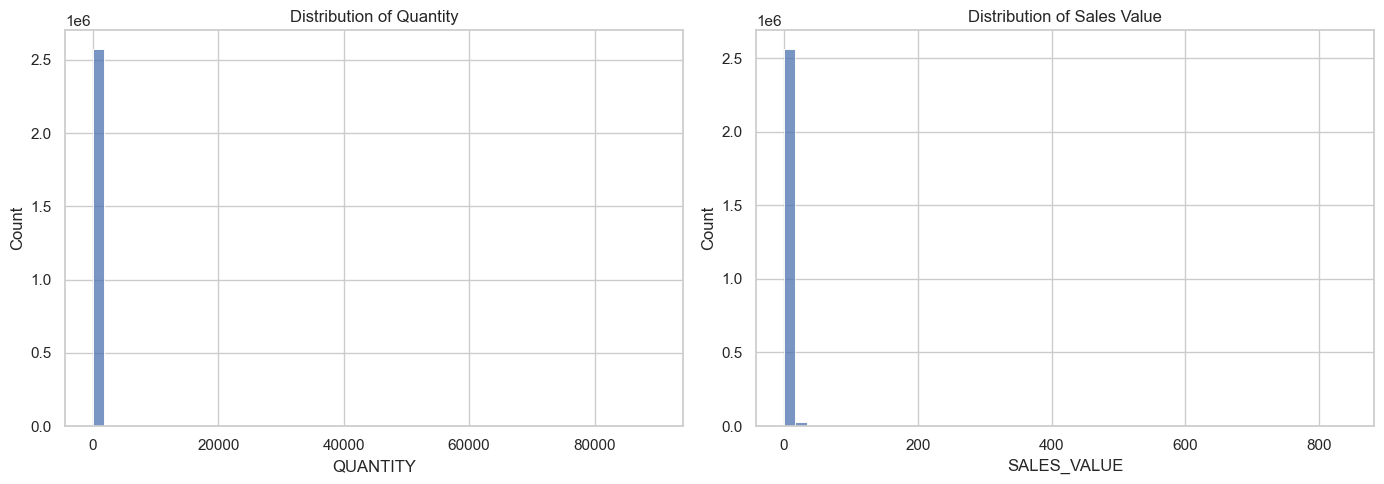

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    transaction["QUANTITY"],
    bins=50,
    ax=axes[0]
)
axes[0].set_title("Distribution of Quantity")

sns.histplot(
    transaction["SALES_VALUE"],
    bins=50,
    ax=axes[1]
)
axes[1].set_title("Distribution of Sales Value")

plt.tight_layout()
plt.show()


In [18]:
transaction[
    ["QUANTITY", "SALES_VALUE", "RETAIL_DISC",
     "COUPON_DISC", "COUPON_MATCH_DISC"]
].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).T

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
QUANTITY,2595732.0,100.428558,1153.436211,0.00,1.00,1.00,1.00,2.00,3.00,10.0,89638.00
SALES_VALUE,2595732.0,3.104120,4.182274,0.00,1.29,2.00,3.49,5.82,7.99,20.0,840.00
RETAIL_DISC,2595732.0,-0.538705,1.249191,-180.00,-0.69,-0.01,0.00,0.00,0.00,0.0,3.99
COUPON_DISC,2595732.0,-0.016416,0.216841,-55.93,0.00,0.00,0.00,0.00,0.00,0.0,0.00
COUPON_MATCH_DISC,2595732.0,-0.002919,0.039690,-7.70,0.00,0.00,0.00,0.00,0.00,0.0,0.00


In [19]:
basket_sales = transaction.groupby(
    "BASKET_ID"
)["SALES_VALUE"].sum()

print(basket_sales.describe())

count    276484.000000
mean         29.142602
std          36.101301
min           0.000000
25%           6.960000
50%          17.070000
75%          36.280000
max         961.490000
Name: SALES_VALUE, dtype: float64


In [20]:
# 1. Top 20 quantities
print("TOP 20 QUANTITY RECORDS")

display(
    transaction.nlargest(20, "QUANTITY")[
        ["household_key", "BASKET_ID", "PRODUCT_ID",
         "QUANTITY", "SALES_VALUE", "RETAIL_DISC"]
    ]
)

TOP 20 QUANTITY RECORDS


,household_key,BASKET_ID,PRODUCT_ID,QUANTITY,SALES_VALUE,RETAIL_DISC
1750942,630,34749153595,6534178,89638,250.00,-13.45
468356,2407,29392047893,6544236,85055,210.00,-8.51
481876,630,29484790880,6534178,61335,150.21,-6.13
166536,149,28210551971,6534178,51912,110.00,-5.19
1340882,193,32956767959,6534178,48073,121.10,-7.21
2472791,2133,41904760458,6534178,45475,100.00,-4.55
1560340,149,33768630428,6534178,41833,115.00,-4.18
376686,149,29035716247,6534178,41686,100.00,-4.17
156049,1406,28167562655,6544236,41485,85.00,-4.15
87625,107,27865225627,6534178,39365,72.00,-3.94


In [21]:
# 2. Top 20 sales values
print("TOP 20 SALES RECORDS")

display(
    transaction.nlargest(20, "SALES_VALUE")[
        ["household_key", "BASKET_ID", "PRODUCT_ID",
         "QUANTITY", "SALES_VALUE", "RETAIL_DISC"]
    ]
)

TOP 20 SALES RECORDS


,household_key,BASKET_ID,PRODUCT_ID,QUANTITY,SALES_VALUE,RETAIL_DISC
1085442,1609,32006114302,12484608,3,840.00,0.00
2030766,346,40387571385,948670,5,631.80,0.00
655985,125,30515165970,1089093,2,505.00,0.00
1152895,374,32187143334,13212959,1,499.99,-50.00
547657,125,30031850855,1089093,1,455.00,0.00
526495,2080,29712930072,1089093,1,430.00,0.00
3600,64,27093315740,1089093,1,400.00,0.00
2352647,2395,41531856879,1089093,1,380.00,0.00
1366400,1109,33028063235,13506935,1,329.99,0.00
807063,2032,31007917779,9296877,25,324.75,0.00


In [22]:
# 3. Positive retail discounts
positive_retail_disc = transaction[
    transaction["RETAIL_DISC"] > 0
]

display(positive_retail_disc.head(20))

# 4. Zero quantity and zero sales records
print("Zero quantity records:")
display(transaction[transaction["QUANTITY"] == 0].head(10))

print("Zero sales records:")
display(transaction[transaction["SALES_VALUE"] == 0].head(10))

,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC
968972,1306,31624096856,310,990941,0,1.000000e-02,340,1.000000e-02,2253,45,0.0,0.0
1001608,1306,31735306143,318,7409789,0,0.000000e+00,381,2.220446e-16,1232,46,0.0,0.0
1023085,1321,31803641901,323,1051069,0,0.000000e+00,364,5.551115e-17,1931,47,0.0,0.0
1023086,1321,31803641901,323,1055863,0,0.000000e+00,364,5.551115e-17,1931,47,0.0,0.0
1067337,37,31944616637,334,8090539,0,0.000000e+00,381,2.220446e-16,1434,48,0.0,0.0
1143255,2241,32173242560,353,995242,0,0.000000e+00,296,2.220446e-16,2325,51,0.0,0.0
1210504,923,32446036423,369,1047226,0,0.000000e+00,410,1.110223e-16,1541,53,0.0,0.0
1215551,1535,32478752229,370,999270,1,7.980000e+00,360,3.990000e+00,1852,54,0.0,0.0
1216489,2491,32478901200,370,13945244,0,4.440892e-16,389,1.110223e-16,1315,54,0.0,0.0
1271754,623,32704598135,384,5995423,1,5.100000e-01,381,2.600000e-01,1950,56,0.0,0.0


Zero quantity records:


,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC
97,744,26985165432,1,5978648,0,0.0,31582,0.0,1119,1,0.00,0.0
128,1287,26985336468,1,5978648,0,0.0,304,0.0,1351,1,0.00,0.0
249,2305,26996870743,2,5978656,0,0.0,414,0.0,1300,1,-1.00,0.0
293,271,26997082949,2,5978656,0,0.0,329,0.0,1719,1,-2.00,0.0
694,315,27008952267,3,957951,0,0.0,327,0.0,1707,1,0.00,0.0
1089,14,27021203242,4,6463658,0,0.0,319,0.0,1704,1,0.00,0.0
1649,2305,27031060487,5,5978648,0,0.0,414,0.0,1100,1,0.00,0.0
1985,100,27045626628,6,5978648,0,0.0,368,0.0,1757,2,0.00,0.0
2142,907,27045792138,6,1125278,0,0.0,313,0.0,1641,2,0.00,0.0
2143,907,27045792138,6,5978656,0,0.0,313,0.0,1641,2,-2.19,0.0


Zero sales records:


,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC
97,744,26985165432,1,5978648,0,0.0,31582,0.00,1119,1,0.0,0.0
128,1287,26985336468,1,5978648,0,0.0,304,0.00,1351,1,0.0,0.0
249,2305,26996870743,2,5978656,0,0.0,414,0.00,1300,1,-1.0,0.0
293,271,26997082949,2,5978656,0,0.0,329,0.00,1719,1,-2.0,0.0
694,315,27008952267,3,957951,0,0.0,327,0.00,1707,1,0.0,0.0
766,2110,27009082349,3,837963,1,0.0,375,0.00,1547,1,0.0,0.0
996,568,27021090189,4,951412,1,0.0,446,-1.48,35,1,0.0,0.0
1089,14,27021203242,4,6463658,0,0.0,319,0.00,1704,1,0.0,0.0
1095,2110,27021248054,4,850115,1,0.0,375,-3.29,1705,1,0.0,0.0
1113,2110,27021248054,4,976872,1,0.0,375,-2.49,1705,1,0.0,0.0


In [23]:
# Inspect product descriptions for unusual quantities
unusual_product_ids = [
    6534178,
    6544236,
    6534166,
    12484608,
    948670,
    1089093
]

display(
    product[
        product["PRODUCT_ID"].isin(unusual_product_ids)
    ]
)

,PRODUCT_ID,MANUFACTURER,DEPARTMENT,BRAND,COMMODITY_DESC,SUB_COMMODITY_DESC,CURR_SIZE_OF_PRODUCT
20643,948670,2,DRUG GM,National,TICKETS,TICKETS,
36327,1089093,2,MISC. TRANS.,National,NO COMMODITY DESCRIPTION,NO SUBCOMMODITY DESCRIPTION,
57216,6534166,69,MISC SALES TRAN,Private,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,
57221,6534178,69,KIOSK-GAS,Private,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,
57335,6544236,69,MISC SALES TRAN,Private,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,
76934,12484608,903,MISC SALES TRAN,Private,COUPON/MISC ITEMS,ELECTRONIC GIFT CARDS ACTIVATI,


In [24]:
print("Positive retail discounts:")
display(
    transaction[transaction["RETAIL_DISC"] > 0].head(20)
)

print("Zero quantity records:")
display(
    transaction[transaction["QUANTITY"] == 0].head(10)
)

print("Zero sales records:")
display(
    transaction[transaction["SALES_VALUE"] == 0].head(10)
)

Positive retail discounts:


,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC
968972,1306,31624096856,310,990941,0,1.000000e-02,340,1.000000e-02,2253,45,0.0,0.0
1001608,1306,31735306143,318,7409789,0,0.000000e+00,381,2.220446e-16,1232,46,0.0,0.0
1023085,1321,31803641901,323,1051069,0,0.000000e+00,364,5.551115e-17,1931,47,0.0,0.0
1023086,1321,31803641901,323,1055863,0,0.000000e+00,364,5.551115e-17,1931,47,0.0,0.0
1067337,37,31944616637,334,8090539,0,0.000000e+00,381,2.220446e-16,1434,48,0.0,0.0
1143255,2241,32173242560,353,995242,0,0.000000e+00,296,2.220446e-16,2325,51,0.0,0.0
1210504,923,32446036423,369,1047226,0,0.000000e+00,410,1.110223e-16,1541,53,0.0,0.0
1215551,1535,32478752229,370,999270,1,7.980000e+00,360,3.990000e+00,1852,54,0.0,0.0
1216489,2491,32478901200,370,13945244,0,4.440892e-16,389,1.110223e-16,1315,54,0.0,0.0
1271754,623,32704598135,384,5995423,1,5.100000e-01,381,2.600000e-01,1950,56,0.0,0.0


Zero quantity records:


,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC
97,744,26985165432,1,5978648,0,0.0,31582,0.0,1119,1,0.00,0.0
128,1287,26985336468,1,5978648,0,0.0,304,0.0,1351,1,0.00,0.0
249,2305,26996870743,2,5978656,0,0.0,414,0.0,1300,1,-1.00,0.0
293,271,26997082949,2,5978656,0,0.0,329,0.0,1719,1,-2.00,0.0
694,315,27008952267,3,957951,0,0.0,327,0.0,1707,1,0.00,0.0
1089,14,27021203242,4,6463658,0,0.0,319,0.0,1704,1,0.00,0.0
1649,2305,27031060487,5,5978648,0,0.0,414,0.0,1100,1,0.00,0.0
1985,100,27045626628,6,5978648,0,0.0,368,0.0,1757,2,0.00,0.0
2142,907,27045792138,6,1125278,0,0.0,313,0.0,1641,2,0.00,0.0
2143,907,27045792138,6,5978656,0,0.0,313,0.0,1641,2,-2.19,0.0


Zero sales records:


,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC
97,744,26985165432,1,5978648,0,0.0,31582,0.00,1119,1,0.0,0.0
128,1287,26985336468,1,5978648,0,0.0,304,0.00,1351,1,0.0,0.0
249,2305,26996870743,2,5978656,0,0.0,414,0.00,1300,1,-1.0,0.0
293,271,26997082949,2,5978656,0,0.0,329,0.00,1719,1,-2.0,0.0
694,315,27008952267,3,957951,0,0.0,327,0.00,1707,1,0.0,0.0
766,2110,27009082349,3,837963,1,0.0,375,0.00,1547,1,0.0,0.0
996,568,27021090189,4,951412,1,0.0,446,-1.48,35,1,0.0,0.0
1089,14,27021203242,4,6463658,0,0.0,319,0.00,1704,1,0.0,0.0
1095,2110,27021248054,4,850115,1,0.0,375,-3.29,1705,1,0.0,0.0
1113,2110,27021248054,4,976872,1,0.0,375,-2.49,1705,1,0.0,0.0


In [25]:
# Examine combinations of quantity and sales value

transaction["quantity_sales_type"] = np.select(
    [
        (transaction["QUANTITY"] == 0) &
        (transaction["SALES_VALUE"] == 0),

        (transaction["QUANTITY"] == 0) &
        (transaction["SALES_VALUE"] > 0),

        (transaction["QUANTITY"] > 0) &
        (transaction["SALES_VALUE"] == 0),

        (transaction["QUANTITY"] > 0) &
        (transaction["SALES_VALUE"] > 0)
    ],
    [
        "Zero quantity and zero sales",
        "Zero quantity but positive sales",
        "Positive quantity but zero sales",
        "Positive quantity and positive sales"
    ],
    default="Other"
)

print(
    transaction["quantity_sales_type"]
    .value_counts()
)

print(
    transaction["quantity_sales_type"]
    .value_counts(normalize=True).mul(100).round(2)
)

quantity_sales_type
Positive quantity and positive sales    2576815
Zero quantity and zero sales              14399
Positive quantity but zero sales           4451
Zero quantity but positive sales             67
Name: count, dtype: int64
quantity_sales_type
Positive quantity and positive sales    99.27
Zero quantity and zero sales             0.55
Positive quantity but zero sales         0.17
Zero quantity but positive sales         0.00
Name: proportion, dtype: float64


In [26]:
# Separate meaningful positive discounts from floating-point noise

print("Positive retail discounts:", 
      (transaction["RETAIL_DISC"] > 0).sum())

print("Tiny positive values:",
      ((transaction["RETAIL_DISC"] > 0) &
       (transaction["RETAIL_DISC"] < 0.000001)).sum())

print("Meaningful positive values:",
      (transaction["RETAIL_DISC"] >= 0.000001).sum())

Positive retail discounts: 36
Tiny positive values: 26
Meaningful positive values: 10


In [27]:
# Inspect all 67 zero-quantity, positive-sales records
display(
    transaction[
        (transaction["QUANTITY"] == 0) &
        (transaction["SALES_VALUE"] > 0)
    ][
        ["household_key", "BASKET_ID", "PRODUCT_ID",
         "QUANTITY", "SALES_VALUE", "RETAIL_DISC",
         "COUPON_DISC"]
    ]
)

,household_key,BASKET_ID,PRODUCT_ID,QUANTITY,SALES_VALUE,RETAIL_DISC,COUPON_DISC
6032,2263,27130336063,986912,0,7.000000e-02,0.00,0.0
136410,435,28085360560,2614183,0,4.000000e-02,0.00,0.0
211149,454,28344946496,914513,0,5.551115e-17,0.00,0.0
211156,454,28344946496,973673,0,5.551115e-17,0.00,0.0
304499,932,28757625745,858732,0,6.661338e-16,0.00,0.0
...,...,...,...,...,...,...,...
2402421,1297,41679039767,854852,0,2.000000e-01,0.00,0.0
2456636,542,41847882142,1121175,0,5.900000e-01,0.59,0.0
2489840,886,41945031242,891648,0,2.220446e-16,0.00,0.0
2584624,2218,42263410261,927238,0,8.881784e-16,0.00,0.0


In [28]:
# Inspect the 10 meaningful positive retail discounts
display(
    transaction[
        transaction["RETAIL_DISC"] >= 0.000001
    ][
        ["household_key", "BASKET_ID", "PRODUCT_ID",
         "QUANTITY", "SALES_VALUE", "RETAIL_DISC"]
    ]
)

,household_key,BASKET_ID,PRODUCT_ID,QUANTITY,SALES_VALUE,RETAIL_DISC
968972,1306,31624096856,990941,0,0.01,0.01
1215551,1535,32478752229,999270,1,7.98,3.99
1271754,623,32704598135,5995423,1,0.51,0.26
1401695,1041,33132710765,895190,0,0.01,0.01
1401698,1041,33132710765,1006573,0,0.00,0.01
1401701,1041,33132710765,1033887,0,0.01,0.01
1417669,249,33180312515,6034857,0,0.79,0.79
1459271,709,33329943095,8090541,0,2.09,2.09
2255342,53,41211916762,12187390,0,0.77,0.77
2456636,542,41847882142,1121175,0,0.59,0.59


In [29]:
# Identify baskets with zero total sales
basket_sales = (
    transaction.groupby("BASKET_ID")["SALES_VALUE"]
    .sum()
)

print("Total baskets:", len(basket_sales))
print("Zero-sales baskets:", (basket_sales == 0).sum())
print("Negative-sales baskets:", (basket_sales < 0).sum())
print("Positive-sales baskets:", (basket_sales > 0).sum())

Total baskets: 276484
Zero-sales baskets: 942
Negative-sales baskets: 0
Positive-sales baskets: 275542


In [30]:
# Creating RFM ready transaction data
rfm_transactions = transaction.copy()

# Calculate actual customer spend
rfm_transactions["CUSTOMER_SPEND"] = (
    rfm_transactions["SALES_VALUE"]
    + rfm_transactions["COUPON_DISC"]
)

# Round to currency precision
rfm_transactions["CUSTOMER_SPEND"] = (
    rfm_transactions["CUSTOMER_SPEND"].round(2)
)

# Retain positive customer-spend transaction lines
rfm_transactions = rfm_transactions[
    rfm_transactions["CUSTOMER_SPEND"] > 0
].copy()

# Check
print("Original rows:", len(transaction))
print("RFM rows:", len(rfm_transactions))
print("Unique households:",
      rfm_transactions["household_key"].nunique())
print("Unique baskets:",
      rfm_transactions["BASKET_ID"].nunique())
print("Total customer spend:",
      round(rfm_transactions["CUSTOMER_SPEND"].sum(), 2))

Original rows: 2595732
RFM rows: 2574125
Unique households: 2500
Unique baskets: 275521
Total customer spend: 8025699.35


In [31]:
# Building the correct basket-level dataset
# Step 1: Calculate customer spend at transaction-line level
transaction["CUSTOMER_SPEND"] = (
    transaction["SALES_VALUE"] +
    transaction["COUPON_DISC"]
).round(2)


# Step 2: Aggregate at basket level
basket_level = (
    transaction
    .groupby(["household_key", "BASKET_ID"])
    .agg(
        BASKET_SPEND=("CUSTOMER_SPEND", "sum"),
        DAY=("DAY", "max")
    )
    .reset_index()
)


# Step 3: Retain baskets with positive customer spend
basket_level = basket_level[
    basket_level["BASKET_SPEND"] > 0
].copy()


# Step 4: Validate
print("Total qualifying baskets:", len(basket_level))
print("Unique households:", basket_level["household_key"].nunique())
print("Total customer spend:",
      round(basket_level["BASKET_SPEND"].sum(), 2))

Total qualifying baskets: 275477
Unique households: 2500
Total customer spend: 8014896.14


In [32]:
# Calculating RFM
# Define reference day as one day after the final observed transaction
reference_day = transaction["DAY"].max() + 1

# Aggregate customer-level RFM metrics
rfm = (
    basket_level
    .groupby("household_key")
    .agg(
        Recency=("DAY", lambda x: reference_day - x.max()),
        Frequency=("BASKET_ID", "nunique"),
        Monetary=("BASKET_SPEND", "sum")
    )
    .reset_index()
)

# Inspect RFM
display(rfm.head())

print(rfm.shape)
print(rfm.describe().round(2))

,household_key,Recency,Frequency,Monetary
0,1,6,85,4249.60
1,2,44,45,1945.34
2,3,9,47,2592.02
3,4,85,30,1197.61
4,5,9,40,779.06


(2500, 4)
       household_key  Recency  Frequency  Monetary
count        2500.00  2500.00    2500.00   2500.00
mean         1250.50    26.58     110.19   3205.96
std           721.83    62.79     115.21   3330.01
min             1.00     1.00       1.00      8.17
25%           625.75     2.00      38.00    965.13
50%          1250.50     7.00      78.00   2149.12
75%          1875.25    21.00     142.00   4392.99
max          2500.00   658.00    1298.00  38240.65


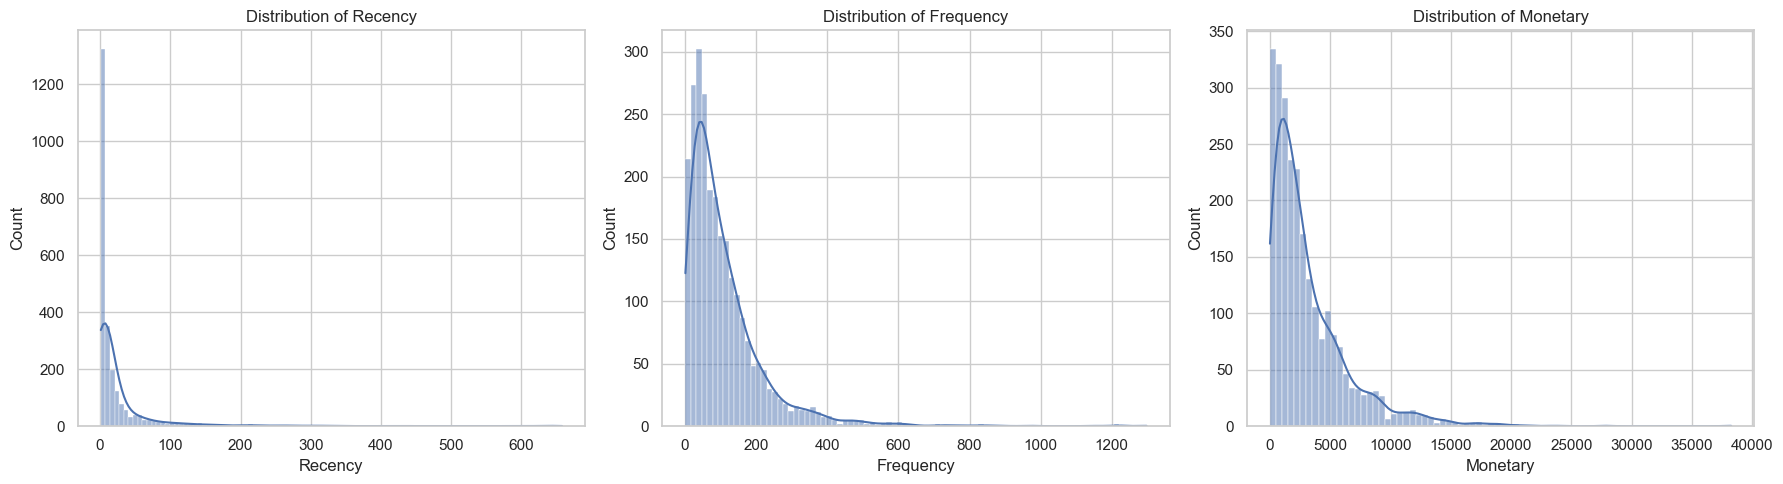

In [33]:
# Examining RFM distrbution
import matplotlib.pyplot as plt
import seaborn as sns

rfm_features = ["Recency", "Frequency", "Monetary"]

# Distribution plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(rfm_features):
    sns.histplot(
        data=rfm,
        x=col,
        kde=True,
        ax=axes[i]
    )
    axes[i].set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

In [34]:
# Calculate skewness
print("Skewness of RFM variables:")

display(
    rfm[rfm_features]
    .skew()
    .to_frame(name="Skewness")
)

Skewness of RFM variables:


,Skewness
Recency,5.574650
Frequency,3.377636
Monetary,2.415190


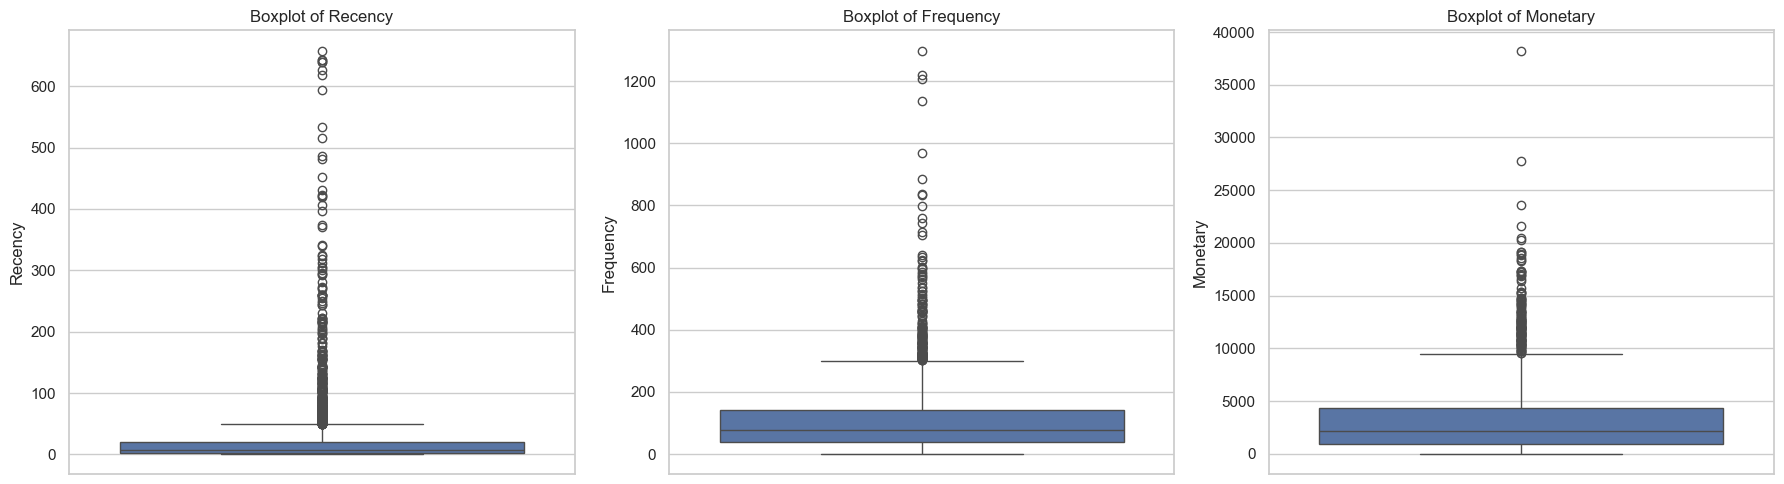

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(rfm_features):
    sns.boxplot(y=rfm[col], ax=axes[i])
    axes[i].set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

#### Applying log transformation due to different numerical scales in the variables and extreme observations can disproportionately influence distances and cluster centroids in K Means

In [36]:
# Create a separate transformed dataset
rfm_log = rfm.copy()

# Apply log transformation to RFM variables
for col in ["Recency", "Frequency", "Monetary"]:
    rfm_log[col] = np.log1p(rfm_log[col])

# Check skewness after transformation
print("Skewness after log transformation:")

display(
    rfm_log[["Recency", "Frequency", "Monetary"]]
    .skew()
    .to_frame(name="Skewness")
)

Skewness after log transformation:


,Skewness
Recency,0.764369
Frequency,-0.403621
Monetary,-0.608260


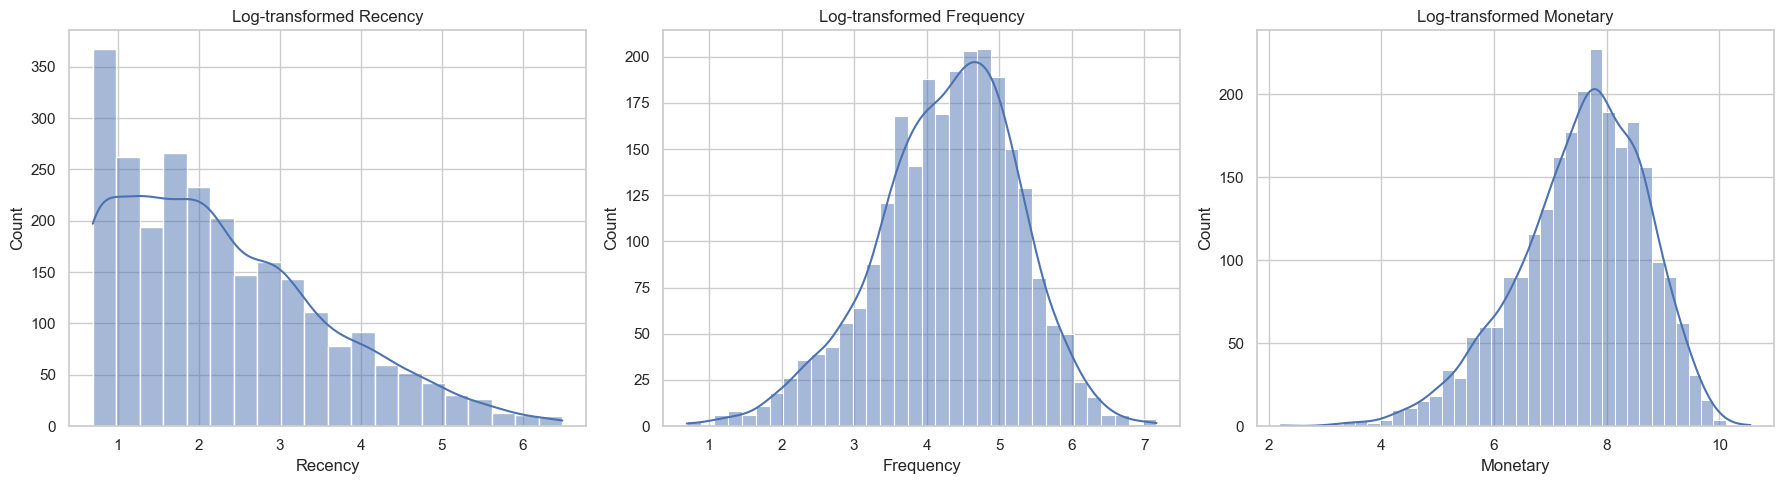

In [37]:
# Visualizing the transformed distribution
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(["Recency", "Frequency", "Monetary"]):
    sns.histplot(
        data=rfm_log,
        x=col,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f"Log-transformed {col}")

plt.tight_layout()
plt.show()

In [38]:
# Using standard scaling method to normalize the data
from sklearn.preprocessing import StandardScaler

# Select transformed RFM features
rfm_features = ["Recency", "Frequency", "Monetary"]

# Initialise scaler
scaler = StandardScaler()

# Fit and transform
rfm_scaled = scaler.fit_transform(
    rfm_log[rfm_features]
)

# Convert back to DataFrame
rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=rfm_features,
    index=rfm_log.index
)

display(rfm_scaled.head())

# Verify scaling
display(rfm_scaled.describe().round(2))

,Recency,Frequency,Monetary
0,-0.269081,0.175750,0.709199
1,1.176724,-0.461442,0.025802
2,0.008056,-0.418101,0.276788
3,1.679975,-0.863341,-0.398342
4,0.008056,-0.578624,-0.774156


,Recency,Frequency,Monetary
count,2500.00,2500.00,2500.00
mean,0.00,0.00,0.00
std,1.00,1.00,1.00
min,-1.24,-3.65,-4.66
25%,-0.93,-0.63,-0.59
50%,-0.17,0.09,0.11
75%,0.62,0.69,0.74
max,3.26,2.94,2.63


### Determining the optimal number of clusters

#### A. Elbow Method

The Elbow Method uses Within-Cluster Sum of Squares (WCSS), also called inertia.

It measures how close customers are to their assigned cluster centroids.

$$WCSS = \sum_{k=1}^{K} \sum_{x_i \in C_k} \|x_i - \mu_k\|^2$$

Where:

* $K =$ Number of clusters.
* $C_k =$ Cluster $k$.
* $x_i =$ Customer observation.
* $\mu_k =$ Centroid of cluster $k$.

As the number of clusters increases, WCSS decreases.

#### B. Silhouette Score

The Silhouette Score measures how well-separated the clusters are.

$$S(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$

Where:

* $a(i)$: Average distance between a customer and other customers in the same cluster.
* $b(i)$: Average distance between that customer and customers in the nearest neighbouring cluster.

The score ranges from -1 to +1.

| Score | Interpretation |
| :--- | :--- |
| Close to +1 | Well-separated clusters |
| Around 0 | Overlapping clusters |
| Negative | Possible incorrect cluster assignment |

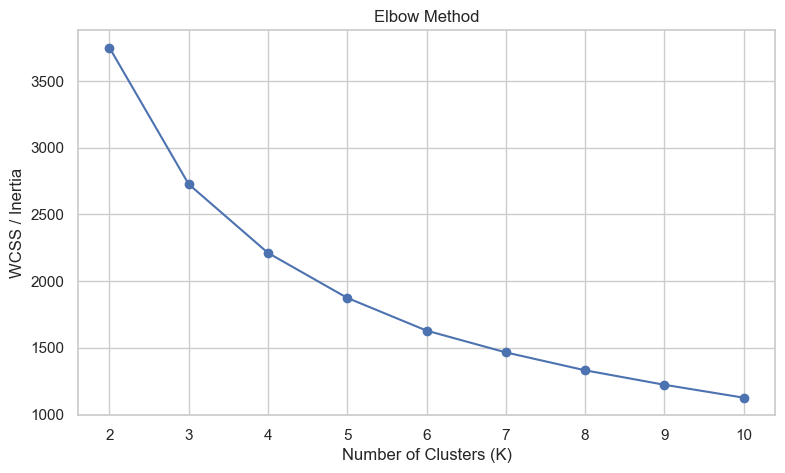

In [39]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Test different numbers of clusters
wcss = []

K = range(2, 11)

for k in K:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)

    wcss.append(kmeans.inertia_)

# Plot Elbow Curve
plt.figure(figsize=(9, 5))

plt.plot(K, wcss, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.title("Elbow Method")

plt.xticks(K)
plt.grid(True)
plt.show()

In [40]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled)

    score = silhouette_score(
        rfm_scaled,
        labels
    )

    silhouette_scores.append(score)

# Display scores
for k, score in zip(range(2, 11), silhouette_scores):
    print(f"K = {k}: Silhouette Score = {score:.4f}")

K = 2: Silhouette Score = 0.4305
K = 3: Silhouette Score = 0.3388
K = 4: Silhouette Score = 0.3286
K = 5: Silhouette Score = 0.2913
K = 6: Silhouette Score = 0.2834
K = 7: Silhouette Score = 0.2796
K = 8: Silhouette Score = 0.2829
K = 9: Silhouette Score = 0.2784
K = 10: Silhouette Score = 0.2761


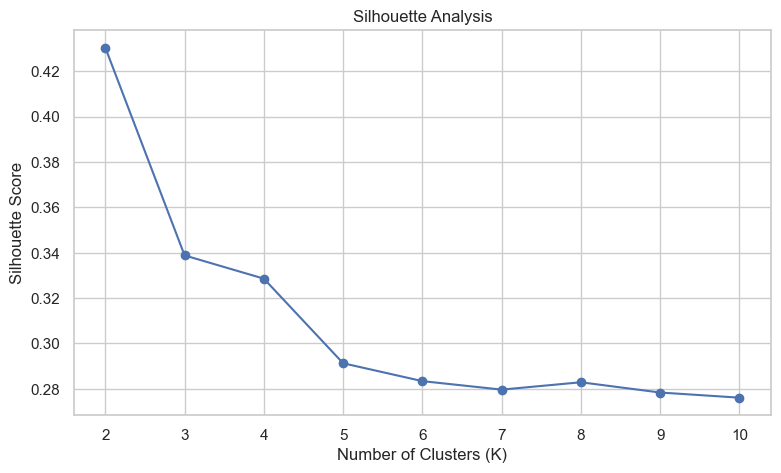

In [41]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis")

plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

In [42]:
# Comparing K = 2, 3 and 4
from sklearn.cluster import KMeans
import pandas as pd

cluster_results = {}
cluster_profiles = {}

for k in [2, 3, 4]:

    # Fit K-means
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled)

    # Create a copy of original RFM data
    temp = rfm.copy()

    # Assign cluster labels
    temp["Cluster"] = labels

    cluster_results[k] = temp

    # Cluster sizes
    print(f"\n========== K = {k} ==========")
    print(temp["Cluster"].value_counts().sort_index())

    # Customer profiles using original values
    profile = (
        temp.groupby("Cluster")
        .agg(
            Customers=("household_key", "count"),
            Recency=("Recency", "median"),
            Frequency=("Frequency", "median"),
            Monetary=("Monetary", "median")
        )
        .round(2)
    )

    cluster_profiles[k] = profile

    display(profile)


========== K = 2 ==========
Cluster
0    1577
1     923
Name: count, dtype: int64


,Customers,Recency,Frequency,Monetary
Cluster,,,,
0,1577,4.0,121.0,3499.31
1,923,26.0,31.0,698.61



========== K = 3 ==========
Cluster
0    1057
1     992
2     451
Name: count, dtype: int64


,Customers,Recency,Frequency,Monetary
Cluster,,,,
0,1057,9.0,57.0,1576.58
1,992,3.0,160.0,4944.85
2,451,57.0,18.0,376.49



========== K = 4 ==========
Cluster
0    930
1    569
2    363
3    638
Name: count, dtype: int64


,Customers,Recency,Frequency,Monetary
Cluster,,,,
0,930,3.0,164.0,5153.96
1,569,23.0,59.0,1782.20
2,363,55.0,15.0,312.50
3,638,4.0,56.0,1407.44


In [43]:
# Detailed profile for K = 4

k4 = cluster_results[4].copy()

cluster_summary = (
    k4.groupby("Cluster")
    .agg(
        Customers=("household_key", "count"),

        Recency_Median=("Recency", "median"),
        Recency_Mean=("Recency", "mean"),

        Frequency_Median=("Frequency", "median"),
        Frequency_Mean=("Frequency", "mean"),

        Monetary_Median=("Monetary", "median"),
        Monetary_Mean=("Monetary", "mean")
    )
    .round(2)
)

display(cluster_summary)

,Customers,Recency_Median,Recency_Mean,Frequency_Median,Frequency_Mean,Monetary_Median,Monetary_Mean
Cluster,,,,,,,
0,930,3.0,4.00,164.0,205.45,5153.96,6107.27
1,569,23.0,40.17,59.0,70.87,1782.20,2153.38
2,363,55.0,101.24,15.0,17.19,312.50,362.72
3,638,4.0,4.88,56.0,59.31,1407.44,1533.22


In [44]:
kmeans_4 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

k4_labels = kmeans_4.fit_predict(rfm_scaled)

print("K = 4 Silhouette Score:",
      round(silhouette_score(rfm_scaled, k4_labels), 4))

print("K = 4 Inertia:",
      round(kmeans_4.inertia_, 2))

K = 4 Silhouette Score: 0.3286
K = 4 Inertia: 2211.47


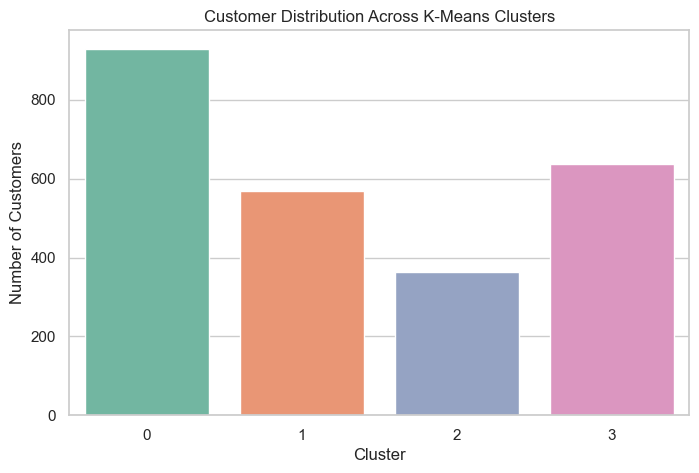

In [45]:
# Visualizing the customer segments

k4 = cluster_results[4].copy()

plt.figure(figsize=(8, 5))

sns.countplot(
    data=k4,
    x="Cluster",
    hue="Cluster",
    palette="Set2",
    legend=False
)

plt.title("Customer Distribution Across K-Means Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")

plt.show()

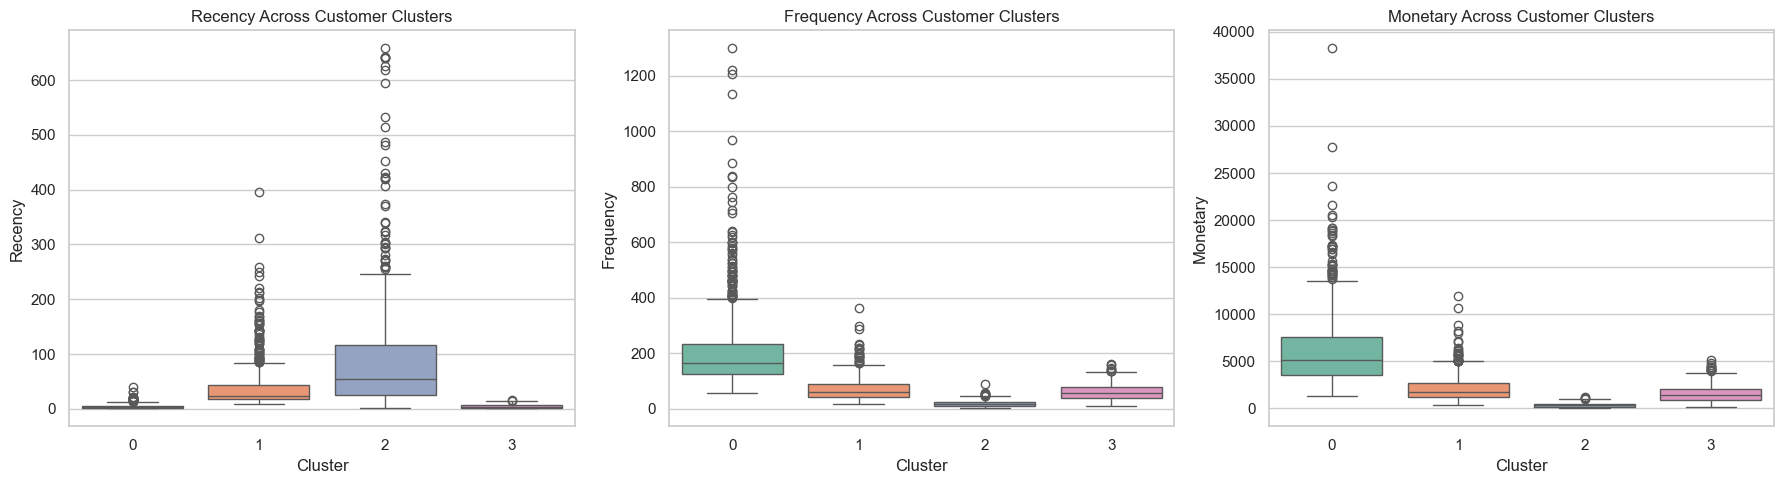

In [46]:
# RFM cluster profiles
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = ["Recency", "Frequency", "Monetary"]

for i, col in enumerate(metrics):

    sns.boxplot(
        data=k4,
        x="Cluster",
        y=col,
        hue="Cluster",
        palette="Set2",
        legend=False,
        ax=axes[i]
    )

    axes[i].set_title(f"{col} Across Customer Clusters")

plt.tight_layout()
plt.show()

In [47]:
# Using PCA to reduce the three-dimensional RFM feature space to two dimensions so we can plot the customers
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

rfm_pca = pca.fit_transform(rfm_scaled)

pca_df = pd.DataFrame(
    rfm_pca,
    columns=["PC1", "PC2"]
)

pca_df["Cluster"] = k4["Cluster"].values

print(
    "Explained variance:",
    pca.explained_variance_ratio_.round(4)
)

print(
    "Total explained variance:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Explained variance: [0.7746 0.1781]
Total explained variance: 95.27 %


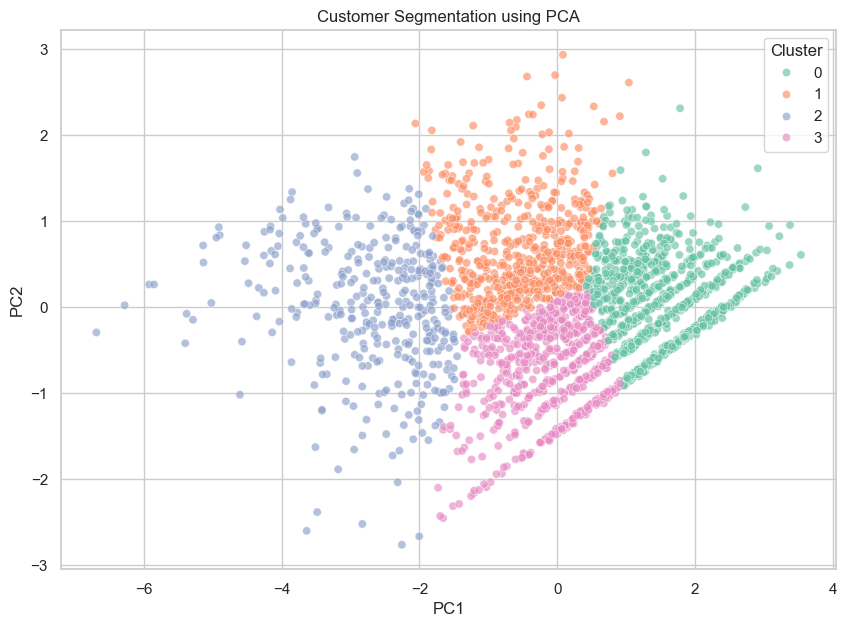

In [48]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set2",
    alpha=0.65
)

plt.title("Customer Segmentation using PCA")
plt.show()

In [49]:
# Inspecting PCA component loadings to understand how much each original RFM variable contributes to the principal components

pca_loadings = pd.DataFrame(
    pca.components_.T,
    columns=["PC1", "PC2"],
    index=["Recency", "Frequency", "Monetary"]
)

display(pca_loadings.round(4))

,PC1,PC2
Recency,-0.5110,0.8573
Frequency,0.6130,0.3123
Monetary,0.6026,0.4093


,Component,Explained_Variance,Cumulative_Variance
0,PC1,0.7746,0.7746
1,PC2,0.1781,0.9527


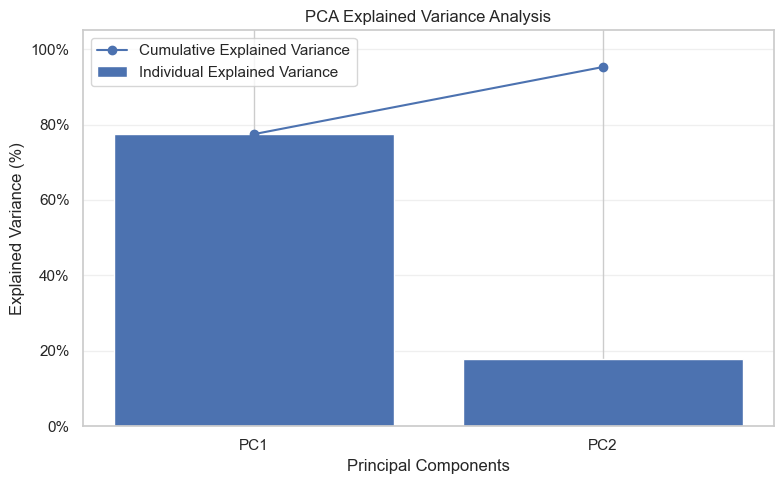

In [50]:
# Create explained variance summary

explained_variance = pd.DataFrame({
    "Component": ["PC1", "PC2"],
    "Explained_Variance": pca.explained_variance_ratio_,
    "Cumulative_Variance": np.cumsum(
        pca.explained_variance_ratio_
    )
})

display(explained_variance.round(4))


# Visualize explained variance

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

plt.figure(figsize=(8, 5))

plt.bar(
    explained_variance["Component"],
    explained_variance["Explained_Variance"],
    label="Individual Explained Variance"
)

plt.plot(
    explained_variance["Component"],
    explained_variance["Cumulative_Variance"],
    marker="o",
    label="Cumulative Explained Variance"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.ylabel("Explained Variance (%)")
plt.xlabel("Principal Components")
plt.title("PCA Explained Variance Analysis")

plt.ylim(0, 1.05)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [51]:
# Attaching cluster lables to RFM
# Create final customer segmentation table

customer_segments = rfm.copy()

customer_segments["Cluster"] = k4["Cluster"].values

# Assign business-friendly names
cluster_names = {
    0: "Champions",
    1: "Valuable but Cooling",
    2: "At-Risk Customers",
    3: "Recent Regulars"
}

customer_segments["Segment"] = (
    customer_segments["Cluster"].map(cluster_names)
)

display(customer_segments.head())

,household_key,Recency,Frequency,Monetary,Cluster,Segment
0,1,6,85,4249.60,0,Champions
1,2,44,45,1945.34,1,Valuable but Cooling
2,3,9,47,2592.02,3,Recent Regulars
3,4,85,30,1197.61,1,Valuable but Cooling
4,5,9,40,779.06,3,Recent Regulars


In [52]:
# Attach customer segment to each transaction
segmented_transactions = transaction.merge(
    customer_segments[
        ["household_key", "Cluster", "Segment"]
    ],
    on="household_key",
    how="left"
)

# Attach product category information
segmented_transactions = segmented_transactions.merge(
    product[
        ["PRODUCT_ID", "DEPARTMENT", "COMMODITY_DESC",
         "SUB_COMMODITY_DESC", "BRAND"]
    ],
    on="PRODUCT_ID",
    how="left"
)

print("Rows:", len(segmented_transactions))
print("Unique households:",
      segmented_transactions["household_key"].nunique())

display(segmented_transactions.head())

Rows: 2595732
Unique households: 2500


,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC,quantity_sales_type,CUSTOMER_SPEND,Cluster,Segment,DEPARTMENT,COMMODITY_DESC,SUB_COMMODITY_DESC,BRAND
0,2375,26984851472,1,1004906,1,1.39,364,-0.60,1631,1,0.0,0.0,Positive quantity and positive sales,1.39,0,Champions,PRODUCE,POTATOES,POTATOES RUSSET (BULK&BAG),Private
1,2375,26984851472,1,1033142,1,0.82,364,0.00,1631,1,0.0,0.0,Positive quantity and positive sales,0.82,0,Champions,PRODUCE,ONIONS,ONIONS SWEET (BULK&BAG),National
2,2375,26984851472,1,1036325,1,0.99,364,-0.30,1631,1,0.0,0.0,Positive quantity and positive sales,0.99,0,Champions,PRODUCE,VEGETABLES - ALL OTHERS,CELERY,Private
3,2375,26984851472,1,1082185,1,1.21,364,0.00,1631,1,0.0,0.0,Positive quantity and positive sales,1.21,0,Champions,PRODUCE,TROPICAL FRUIT,BANANAS,National
4,2375,26984851472,1,8160430,1,1.50,364,-0.39,1631,1,0.0,0.0,Positive quantity and positive sales,1.50,0,Champions,PRODUCE,ORGANICS FRUIT & VEGETABLES,ORGANIC CARROTS,Private


### Calculate spending by department and customer segment
Customer Spend = SALES_VALUE + COUPON_DISC

In [53]:
# Calculate customer spend
segmented_transactions["CUSTOMER_SPEND"] = (
    segmented_transactions["SALES_VALUE"]
    + segmented_transactions["COUPON_DISC"]
).round(2)

# Aggregate spending by segment and department
department_analysis = (
    segmented_transactions
    .groupby(["Segment", "DEPARTMENT"])
    .agg(
        Total_Spend=("CUSTOMER_SPEND", "sum"),
        Transaction_Lines=("BASKET_ID", "count"),
        Unique_Customers=("household_key", "nunique")
    )
    .reset_index()
)

display(
    department_analysis.sort_values(
        ["Segment", "Total_Spend"],
        ascending=[True, False]
    ).head(30)
)

,Segment,DEPARTMENT,Total_Spend,Transaction_Lines,Unique_Customers
12,At-Risk Customers,GROCERY,68047.02,27681,363
7,At-Risk Customers,DRUG GM,17528.75,4724,355
20,At-Risk Customers,PRODUCE,9705.95,4417,328
14,At-Risk Customers,MEAT,8374.44,1414,267
15,At-Risk Customers,MEAT-PCKGD,8150.90,2322,297
13,At-Risk Customers,KIOSK-GAS,5097.83,243,89
6,At-Risk Customers,DELI,3861.39,927,226
19,At-Risk Customers,PASTRY,3070.45,863,242
18,At-Risk Customers,NUTRITION,2134.79,686,133
16,At-Risk Customers,MISC SALES TRAN,1075.33,74,58


In [54]:
# Identify qualifying purchase occasions
qualifying_baskets = basket_level[
    ["household_key", "BASKET_ID"]
].drop_duplicates()

# Retain all transaction lines from qualifying baskets
marketing_transactions = segmented_transactions.merge(
    qualifying_baskets,
    on=["household_key", "BASKET_ID"],
    how="inner"
)

print("Qualifying transaction rows:",
      len(marketing_transactions))

print("Total customer spend:",
      round(marketing_transactions["CUSTOMER_SPEND"].sum(), 2))

Qualifying transaction rows: 2594547
Total customer spend: 8014896.14


In [55]:
# Calculate department spending and category contribution
# Check missing department information
print("Missing departments:",
      marketing_transactions["DEPARTMENT"].isna().sum())

print("Blank departments:",
      marketing_transactions["DEPARTMENT"].eq("").sum())

# Aggregate department performance
department_analysis = (
    marketing_transactions
    .groupby(["Segment", "DEPARTMENT"])
    .agg(
        Total_Spend=("CUSTOMER_SPEND", "sum"),
        Transaction_Lines=("BASKET_ID", "count"),
        Unique_Customers=("household_key", "nunique")
    )
    .reset_index()
)

# Exclude unidentified departments from the ranking,
# but retain the diagnostic counts above.
department_analysis = department_analysis[
    department_analysis["DEPARTMENT"].notna() &
    (department_analysis["DEPARTMENT"] != "")
].copy()

# Calculate each department's contribution to its segment
department_analysis["Spend_Share"] = (
    department_analysis["Total_Spend"] /
    department_analysis.groupby("Segment")["Total_Spend"]
    .transform("sum") * 100
).round(2)

# Rank departments within each segment
department_analysis["Rank"] = (
    department_analysis.groupby("Segment")["Total_Spend"]
    .rank(method="first", ascending=False)
)

# Display top 5 departments for every segment
top_departments = (
    department_analysis[
        department_analysis["Rank"] <= 5
    ]
    .sort_values(["Segment", "Rank"])
)

display(top_departments)

Missing departments: 0
Blank departments: 0


,Segment,DEPARTMENT,Total_Spend,Transaction_Lines,Unique_Customers,Spend_Share,Rank
12,At-Risk Customers,GROCERY,68045.73,27672,363,51.68,1.0
7,At-Risk Customers,DRUG GM,17528.75,4720,355,13.31,2.0
20,At-Risk Customers,PRODUCE,9705.95,4416,328,7.37,3.0
14,At-Risk Customers,MEAT,8374.44,1414,267,6.36,4.0
15,At-Risk Customers,MEAT-PCKGD,8150.90,2321,297,6.19,5.0
45,Champions,GROCERY,2835536.25,1139083,930,49.92,1.0
38,Champions,DRUG GM,756227.61,199159,930,13.31,2.0
48,Champions,KIOSK-GAS,444624.86,17742,680,7.83,3.0
60,Champions,PRODUCE,394609.76,182079,929,6.95,4.0
49,Champions,MEAT,371051.50,59984,918,6.53,5.0


### Customer penetration analysis by department

In [56]:
# Number of customers in each segment
segment_sizes = (
    customer_segments
    .groupby("Segment")["household_key"]
    .nunique()
)

# Unique customers purchasing from each department
department_penetration = (
    marketing_transactions
    .groupby(["Segment", "DEPARTMENT"])
    .agg(
        Unique_Customers=("household_key", "nunique"),
        Department_Spend=("CUSTOMER_SPEND", "sum")
    )
    .reset_index()
)

# Add total segment population
department_penetration["Segment_Size"] = (
    department_penetration["Segment"]
    .map(segment_sizes)
)

# Calculate customer penetration
department_penetration["Penetration_Pct"] = (
    department_penetration["Unique_Customers"] /
    department_penetration["Segment_Size"] * 100
).round(2)

# Calculate spending per purchasing customer
department_penetration["Spend_Per_Buyer"] = (
    department_penetration["Department_Spend"] /
    department_penetration["Unique_Customers"]
).round(2)

# Display top 10 departments by spending for each segment
department_penetration["Rank"] = (
    department_penetration
    .groupby("Segment")["Department_Spend"]
    .rank(method="first", ascending=False)
)

display(
    department_penetration[
        department_penetration["Rank"] <= 10
    ].sort_values(["Segment", "Rank"])
)

,Segment,DEPARTMENT,Unique_Customers,Department_Spend,Segment_Size,Penetration_Pct,Spend_Per_Buyer,Rank
12,At-Risk Customers,GROCERY,363,68045.73,363,100.00,187.45,1.0
7,At-Risk Customers,DRUG GM,355,17528.75,363,97.80,49.38,2.0
20,At-Risk Customers,PRODUCE,328,9705.95,363,90.36,29.59,3.0
14,At-Risk Customers,MEAT,267,8374.44,363,73.55,31.36,4.0
15,At-Risk Customers,MEAT-PCKGD,297,8150.90,363,81.82,27.44,5.0
13,At-Risk Customers,KIOSK-GAS,89,5097.83,363,24.52,57.28,6.0
6,At-Risk Customers,DELI,226,3861.39,363,62.26,17.09,7.0
19,At-Risk Customers,PASTRY,242,3070.45,363,66.67,12.69,8.0
18,At-Risk Customers,NUTRITION,133,2134.79,363,36.64,16.05,9.0
16,At-Risk Customers,MISC SALES TRAN,58,1075.33,363,15.98,18.54,10.0


### Customer category breadth analysis

In [57]:
# Count distinct departments purchased by each household

customer_category_breadth = (
    marketing_transactions
    .groupby("household_key")
    .agg(
        Category_Breadth=("DEPARTMENT", "nunique")
    )
    .reset_index()
)

# Attach customer segments
customer_category_breadth = customer_category_breadth.merge(
    customer_segments[
        ["household_key", "Segment"]
    ],
    on="household_key",
    how="left"
)

# Compare category breadth across segments
breadth_summary = (
    customer_category_breadth
    .groupby("Segment")
    .agg(
        Customers=("household_key", "count"),
        Mean_Categories=("Category_Breadth", "mean"),
        Median_Categories=("Category_Breadth", "median"),
        Min_Categories=("Category_Breadth", "min"),
        Max_Categories=("Category_Breadth", "max")
    )
    .round(2)
)

display(breadth_summary)

,Customers,Mean_Categories,Median_Categories,Min_Categories,Max_Categories
Segment,,,,,
At-Risk Customers,363,7.80,8.0,1,14
Champions,930,15.88,16.0,6,24
Recent Regulars,638,11.65,12.0,5,20
Valuable but Cooling,569,12.64,13.0,7,21


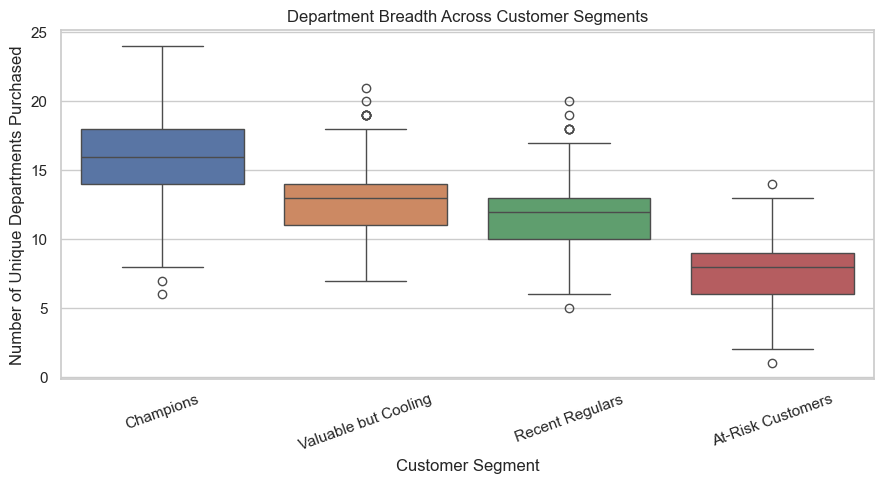

In [58]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=customer_category_breadth,
    x="Segment",
    y="Category_Breadth",
    hue="Segment",
    legend=False
)

plt.title("Department Breadth Across Customer Segments")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Unique Departments Purchased")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

### Statistical validation: Kruskal-Wallis test

Using the Kruskal-Wallis test since department breadth is a count variable and the group distributions need not be normally distributed.

Our hypotheses:

$$H_0 : \text{All four segments have the same breadth distribution}$$

$$H_1 : \text{At least one segment differs}$$

In [59]:
from scipy.stats import kruskal

# Extract category breadth for each segment
groups = [
    group["Category_Breadth"].values
    for name, group in customer_category_breadth.groupby("Segment")
]

# Perform Kruskal-Wallis test
statistic, p_value = kruskal(*groups)

print("Kruskal-Wallis H-statistic:", round(statistic, 4))
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: At least one segment differs significantly.")
else:
    print("Fail to reject H0: No significant difference established.")

Kruskal-Wallis H-statistic: 1275.8487
P-value: 2.559497913239801e-276
Reject H0: At least one segment differs significantly.


In [60]:
### Calculating the number of distinct departments per 10 purchase occasions
# Calculate distinct departments and purchase frequency
customer_breadth_frequency = (
    marketing_transactions
    .groupby("household_key")
    .agg(
        Category_Breadth=("DEPARTMENT", "nunique"),
        Frequency=("BASKET_ID", "nunique")
    )
    .reset_index()
)

# Attach customer segments
customer_breadth_frequency = customer_breadth_frequency.merge(
    customer_segments[["household_key", "Segment"]],
    on="household_key",
    how="left"
)

# Departments per 10 purchase occasions
customer_breadth_frequency["Breadth_per_10_Baskets"] = (
    customer_breadth_frequency["Category_Breadth"] /
    customer_breadth_frequency["Frequency"] * 10
)

# Compare across segments
display(
    customer_breadth_frequency
    .groupby("Segment")
    .agg(
        Customers=("household_key", "count"),
        Median_Breadth=("Category_Breadth", "median"),
        Median_Frequency=("Frequency", "median"),
        Median_Breadth_per_10_Baskets=(
            "Breadth_per_10_Baskets", "median"
        )
    )
    .round(2)
)

,Customers,Median_Breadth,Median_Frequency,Median_Breadth_per_10_Baskets
Segment,,,,
At-Risk Customers,363,8.0,15.0,5.29
Champions,930,16.0,164.0,0.91
Recent Regulars,638,12.0,56.0,2.17
Valuable but Cooling,569,13.0,59.0,2.03


### Pairwise statistical comparisons
Using the Mann-Whitney U test for pairwise comparisons, followed by Holm correction to control for multiple testing.

In [61]:
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
import pandas as pd

# Define customer segments
segments = customer_category_breadth["Segment"].unique()

results = []

# Pairwise Mann-Whitney U tests
for seg1, seg2 in combinations(segments, 2):

    group1 = customer_category_breadth.loc[
        customer_category_breadth["Segment"] == seg1,
        "Category_Breadth"
    ]

    group2 = customer_category_breadth.loc[
        customer_category_breadth["Segment"] == seg2,
        "Category_Breadth"
    ]

    stat, p = mannwhitneyu(
        group1,
        group2,
        alternative="two-sided"
    )

    results.append({
        "Segment_1": seg1,
        "Segment_2": seg2,
        "U_Statistic": stat,
        "Raw_P_Value": p
    })

# Apply Holm correction
results_df = pd.DataFrame(results)

results_df["Adjusted_P_Value"] = multipletests(
    results_df["Raw_P_Value"],
    method="holm"
)[1]

results_df["Significant"] = (
    results_df["Adjusted_P_Value"] < 0.05
)

display(results_df.round(6))

,Segment_1,Segment_2,U_Statistic,Raw_P_Value,Adjusted_P_Value,Significant
0,Champions,Valuable but Cooling,422389.5,0.0,0.0,True
1,Champions,Recent Regulars,510804.0,0.0,0.0,True
2,Champions,At-Risk Customers,331966.5,0.0,0.0,True
3,Valuable but Cooling,Recent Regulars,219183.5,0.0,0.0,True
4,Valuable but Cooling,At-Risk Customers,189590.5,0.0,0.0,True
5,Recent Regulars,At-Risk Customers,200106.0,0.0,0.0,True


In [62]:
# Compare category breadth using equal purchase opportunities
# Number of distinct baskets per household
household_frequency = (
    marketing_transactions
    .groupby("household_key")["BASKET_ID"]
    .nunique()
)

print("Customers with at least 10 baskets:",
      (household_frequency >= 10).sum())

print("Customers with fewer than 10 baskets:",
      (household_frequency < 10).sum())

Customers with at least 10 baskets: 2402
Customers with fewer than 10 baskets: 98


### Equal purchase opportunity analysis
Selecting exactly 10 distinct baskets per qualifying customer and calculate how many different departments they purchased from across those baskets.

In [63]:
# Select 10 baskets per customer
# Get unique qualifying purchase occasions
unique_baskets = (
    basket_level[
        ["household_key", "BASKET_ID"]
    ]
    .drop_duplicates()
)

# Retain customers with at least 10 baskets
eligible_households = (
    unique_baskets.groupby("household_key")
    .size()
)

eligible_households = eligible_households[
    eligible_households >= 10
].index

eligible_baskets = unique_baskets[
    unique_baskets["household_key"].isin(eligible_households)
]

# Randomly select exactly 10 baskets per household
selected_baskets = (
    eligible_baskets
    .groupby("household_key", group_keys=False)
    .sample(n=10, random_state=42)
)

print("Selected baskets:", len(selected_baskets))
print("Unique customers:", selected_baskets["household_key"].nunique())

print(
    selected_baskets.groupby("household_key")
    .size().value_counts()
)

Selected baskets: 24020
Unique customers: 2402
10    2402
Name: count, dtype: int64


In [64]:
# Calculate department breadth
# Retrieve all transaction lines belonging to selected baskets
equal_basket_transactions = marketing_transactions.merge(
    selected_baskets,
    on=["household_key", "BASKET_ID"],
    how="inner"
)

# Calculate category breadth across the 10 baskets
equal_basket_breadth = (
    equal_basket_transactions
    .groupby("household_key")
    .agg(
        Category_Breadth=("DEPARTMENT", "nunique")
    )
    .reset_index()
)

# Attach customer segment
equal_basket_breadth = equal_basket_breadth.merge(
    customer_segments[["household_key", "Segment"]],
    on="household_key",
    how="left"
)

# Summarise
equal_basket_summary = (
    equal_basket_breadth
    .groupby("Segment")
    .agg(
        Customers=("household_key", "count"),
        Mean_Breadth=("Category_Breadth", "mean"),
        Median_Breadth=("Category_Breadth", "median"),
        Min_Breadth=("Category_Breadth", "min"),
        Max_Breadth=("Category_Breadth", "max")
    )
    .round(2)
)

display(equal_basket_summary)

,Customers,Mean_Breadth,Median_Breadth,Min_Breadth,Max_Breadth
Segment,,,,,
At-Risk Customers,267,6.85,7.0,1,13
Champions,930,8.15,8.0,1,16
Recent Regulars,636,7.44,7.0,2,13
Valuable but Cooling,569,7.93,8.0,2,16


In [65]:
# Statistical test
groups = [
    group["Category_Breadth"].values
    for _, group in equal_basket_breadth.groupby("Segment")
]

statistic, p_value = kruskal(*groups)

print("Kruskal-Wallis H-statistic:", round(statistic, 4))
print("P-value:", p_value)

Kruskal-Wallis H-statistic: 86.7641
P-value: 1.085032919554473e-18


In [66]:
# Pairwise comparison after equalising baskets to determine which segment pairs still differ significantly
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
import pandas as pd

results_equal = []

segments = equal_basket_breadth["Segment"].unique()

for seg1, seg2 in combinations(segments, 2):

    group1 = equal_basket_breadth.loc[
        equal_basket_breadth["Segment"] == seg1,
        "Category_Breadth"
    ]

    group2 = equal_basket_breadth.loc[
        equal_basket_breadth["Segment"] == seg2,
        "Category_Breadth"
    ]

    stat, p = mannwhitneyu(
        group1,
        group2,
        alternative="two-sided"
    )

    results_equal.append({
        "Segment_1": seg1,
        "Segment_2": seg2,
        "U_Statistic": stat,
        "Raw_P_Value": p
    })

results_equal = pd.DataFrame(results_equal)

results_equal["Adjusted_P_Value"] = multipletests(
    results_equal["Raw_P_Value"],
    method="holm"
)[1]

results_equal["Significant"] = (
    results_equal["Adjusted_P_Value"] < 0.05
)

display(results_equal.round(6))

,Segment_1,Segment_2,U_Statistic,Raw_P_Value,Adjusted_P_Value,Significant
0,Champions,Valuable but Cooling,279671.0,0.060869,0.060869,False
1,Champions,Recent Regulars,349114.0,0.000000,0.000000,True
2,Champions,At-Risk Customers,164132.5,0.000000,0.000000,True
3,Valuable but Cooling,Recent Regulars,203989.5,0.000112,0.000336,True
4,Valuable but Cooling,At-Risk Customers,96818.0,0.000000,0.000000,True
5,Recent Regulars,At-Risk Customers,98085.5,0.000197,0.000395,True


### Brand preference analysis

In [67]:
# Inspect brand classifications
print("Brand classifications:")

display(
    product["BRAND"]
    .value_counts(dropna=False)
)

# Check brand spending across segments
brand_analysis = (
    marketing_transactions
    .groupby(["Segment", "BRAND"], dropna=False)
    .agg(
        Total_Spend=("CUSTOMER_SPEND", "sum"),
        Unique_Customers=("household_key", "nunique"),
        Transaction_Lines=("BASKET_ID", "count")
    )
    .reset_index()
)

# Calculate spending share within each segment
brand_analysis["Spend_Share"] = (
    brand_analysis["Total_Spend"] /
    brand_analysis.groupby("Segment")["Total_Spend"]
    .transform("sum") * 100
).round(2)

display(
    brand_analysis.sort_values(
        ["Segment", "Total_Spend"],
        ascending=[True, False]
    )
)

Brand classifications:


BRAND
National    78537
Private     13816
Name: count, dtype: int64

,Segment,BRAND,Total_Spend,Unique_Customers,Transaction_Lines,Spend_Share
0,At-Risk Customers,National,96931.07,363,31237,73.62
1,At-Risk Customers,Private,34736.83,359,12978,26.38
2,Champions,National,4058556.84,930,1295432,71.46
3,Champions,Private,1621202.76,930,515050,28.54
4,Recent Regulars,National,729261.22,638,238617,74.55
5,Recent Regulars,Private,248933.27,638,97973,25.45
6,Valuable but Cooling,National,893823.69,569,283203,72.95
7,Valuable but Cooling,Private,331450.46,569,120057,27.05


In [68]:
# Calculateing Private brand spending share at customer level
# Calculate household-level National and Private spending

customer_brand_spend = (
    marketing_transactions
    .pivot_table(
        index="household_key",
        columns="BRAND",
        values="CUSTOMER_SPEND",
        aggfunc="sum",
        fill_value=0
    )
    .reset_index()
)

# Calculate total brand spending
customer_brand_spend["Total_Brand_Spend"] = (
    customer_brand_spend["National"] +
    customer_brand_spend["Private"]
)

# Calculate Private brand spending share
customer_brand_spend["Private_Spend_Share"] = (
    customer_brand_spend["Private"] /
    customer_brand_spend["Total_Brand_Spend"] * 100
)

# Attach customer segment
customer_brand_spend = customer_brand_spend.merge(
    customer_segments[["household_key", "Segment"]],
    on="household_key",
    how="left"
)

# Summarise by segment
brand_customer_summary = (
    customer_brand_spend
    .groupby("Segment")
    .agg(
        Customers=("household_key", "count"),
        Mean_Private_Share=("Private_Spend_Share", "mean"),
        Median_Private_Share=("Private_Spend_Share", "median"),
        Std_Private_Share=("Private_Spend_Share", "std")
    )
    .round(2)
)

display(brand_customer_summary)

,Customers,Mean_Private_Share,Median_Private_Share,Std_Private_Share
Segment,,,,
At-Risk Customers,363,27.16,24.70,14.16
Champions,930,28.52,27.69,11.31
Recent Regulars,638,26.01,24.85,11.41
Valuable but Cooling,569,27.25,26.13,11.00


#### The hypotheses:

$$H_0 : \text{All four segments have the same distribution of Private brand share}$$

$$H_1 : \text{At least one segment differs}$$

In [69]:
# Test whether the differences are statistically significant
groups = [
    group["Private_Spend_Share"].values
    for _, group in customer_brand_spend.groupby("Segment")
]

statistic, p_value = kruskal(*groups)

print("Kruskal-Wallis H-statistic:", round(statistic, 4))
print("P-value:", p_value)

Kruskal-Wallis H-statistic: 24.6158
P-value: 1.8576946248095968e-05


In [70]:
# Identifying which segments actually differ using pairwise Mann-Whitney tests with Holm correction
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
import pandas as pd

brand_pairwise = []

segments = customer_brand_spend["Segment"].unique()

for seg1, seg2 in combinations(segments, 2):

    group1 = customer_brand_spend.loc[
        customer_brand_spend["Segment"] == seg1,
        "Private_Spend_Share"
    ]

    group2 = customer_brand_spend.loc[
        customer_brand_spend["Segment"] == seg2,
        "Private_Spend_Share"
    ]

    stat, p = mannwhitneyu(
        group1,
        group2,
        alternative="two-sided"
    )

    brand_pairwise.append({
        "Segment_1": seg1,
        "Segment_2": seg2,
        "U_Statistic": stat,
        "Raw_P_Value": p
    })

brand_pairwise = pd.DataFrame(brand_pairwise)

brand_pairwise["Adjusted_P_Value"] = multipletests(
    brand_pairwise["Raw_P_Value"],
    method="holm"
)[1]

brand_pairwise["Significant"] = (
    brand_pairwise["Adjusted_P_Value"] < 0.05
)

display(brand_pairwise.round(6))

,Segment_1,Segment_2,U_Statistic,Raw_P_Value,Adjusted_P_Value,Significant
0,Champions,Valuable but Cooling,282325.0,0.029171,0.112023,False
1,Champions,Recent Regulars,338371.0,0.000002,0.000013,True
2,Champions,At-Risk Customers,186992.0,0.002562,0.012811,True
3,Valuable but Cooling,Recent Regulars,194794.0,0.028006,0.112023,False
4,Valuable but Cooling,At-Risk Customers,108365.0,0.203939,0.407878,False
5,Recent Regulars,At-Risk Customers,113705.0,0.634352,0.634352,False


### Campaign and coupon effectiveness analysis

In [71]:
# Campaign overview

print("Campaign Description:")
display(campaign_desc.head())

print("\nCampaign Table:")
display(campaign_table.head())

print("\nCoupon Mapping:")
display(coupon.head())

print("\nCoupon Redemption:")
display(coupon_redempt.head())

print("\nCausal Data:")
display(causal.head())

Campaign Description:


,DESCRIPTION,CAMPAIGN,START_DAY,END_DAY
0,TypeB,24,659,719
1,TypeC,15,547,708
2,TypeB,25,659,691
3,TypeC,20,615,685
4,TypeB,23,646,684



Campaign Table:


,DESCRIPTION,household_key,CAMPAIGN
0,TypeA,17,26
1,TypeA,27,26
2,TypeA,212,26
3,TypeA,208,26
4,TypeA,192,26



Coupon Mapping:


,COUPON_UPC,PRODUCT_ID,CAMPAIGN
0,10000089061,27160,4
1,10000089064,27754,9
2,10000089073,28897,12
3,51800009050,28919,28
4,52100000076,28929,25



Coupon Redemption:


,household_key,DAY,COUPON_UPC,CAMPAIGN
0,1,421,10000085364,8
1,1,421,51700010076,8
2,1,427,54200000033,8
3,1,597,10000085476,18
4,1,597,54200029176,18



Causal Data:


,PRODUCT_ID,STORE_ID,WEEK_NO,display,mailer
0,26190,286,70,0,A
1,26190,288,70,0,A
2,26190,289,70,0,A
3,26190,292,70,0,A
4,26190,293,70,0,A


In [72]:
campaign_datasets = {
    "Campaign Description": campaign_desc,
    "Campaign Table": campaign_table,
    "Coupon": coupon,
    "Coupon Redemption": coupon_redempt,
    "Causal": causal
}

for name, df in campaign_datasets.items():

    print(f"\n{name}")
    print("Shape:", df.shape)
    print("Missing values:", df.isna().sum().sum())
    print("Unique campaigns:",
          df["CAMPAIGN"].nunique()
          if "CAMPAIGN" in df.columns else "Not available")


Campaign Description
Shape: (30, 4)
Missing values: 0
Unique campaigns: 30

Campaign Table
Shape: (7208, 3)
Missing values: 0
Unique campaigns: 30

Coupon
Shape: (124548, 3)
Missing values: 0
Unique campaigns: 30

Coupon Redemption
Shape: (2318, 4)
Missing values: 0
Unique campaigns: 30

Causal
Shape: (36786524, 5)
Missing values: 0
Unique campaigns: Not available


In [73]:
# Inspecting campign tables
print("CAMPAIGN DESCRIPTION")
display(campaign_desc.head(10))

print("CAMPAIGN TABLE")
display(campaign_table.head(10))

print("COUPON MAPPING")
display(coupon.head(10))

print("COUPON REDEMPTION")
display(coupon_redempt.head(10))

CAMPAIGN DESCRIPTION


,DESCRIPTION,CAMPAIGN,START_DAY,END_DAY
0,TypeB,24,659,719
1,TypeC,15,547,708
2,TypeB,25,659,691
3,TypeC,20,615,685
4,TypeB,23,646,684
5,TypeB,21,624,656
6,TypeB,22,624,656
7,TypeA,18,587,642
8,TypeB,19,603,635
9,TypeB,17,575,607


CAMPAIGN TABLE


,DESCRIPTION,household_key,CAMPAIGN
0,TypeA,17,26
1,TypeA,27,26
2,TypeA,212,26
3,TypeA,208,26
4,TypeA,192,26
5,TypeA,187,26
6,TypeA,183,26
7,TypeA,142,26
8,TypeA,140,26
9,TypeA,134,26


COUPON MAPPING


,COUPON_UPC,PRODUCT_ID,CAMPAIGN
0,10000089061,27160,4
1,10000089064,27754,9
2,10000089073,28897,12
3,51800009050,28919,28
4,52100000076,28929,25
5,52100000031,28929,22
6,52100000033,28929,9
7,52100026076,28929,28
8,52100020075,28929,1
9,52100000076,29096,25


COUPON REDEMPTION


,household_key,DAY,COUPON_UPC,CAMPAIGN
0,1,421,10000085364,8
1,1,421,51700010076,8
2,1,427,54200000033,8
3,1,597,10000085476,18
4,1,597,54200029176,18
5,8,422,53600000078,8
6,13,396,53700048182,5
7,13,424,10000085364,8
8,13,434,53600000078,8
9,13,447,52370020076,8


In [74]:
# Campaign distribution
print("Number of campaigns:",
      campaign_desc["CAMPAIGN"].nunique())

print("\nCampaign duration:")

campaign_desc["Duration"] = (
    campaign_desc["END_DAY"] -
    campaign_desc["START_DAY"] + 1
)

display(
    campaign_desc[
        ["CAMPAIGN", "DESCRIPTION", "START_DAY",
         "END_DAY", "Duration"]
    ].sort_values("CAMPAIGN")
)

Number of campaigns: 30

Campaign duration:


,CAMPAIGN,DESCRIPTION,START_DAY,END_DAY,Duration
23,1,TypeB,346,383,38
24,2,TypeB,351,383,33
20,3,TypeC,356,412,57
22,4,TypeB,372,404,33
21,5,TypeB,377,411,35
19,6,TypeC,393,425,33
18,7,TypeB,398,432,35
17,8,TypeA,412,460,49
16,9,TypeB,435,467,33
15,10,TypeB,463,495,33


In [75]:
# Household campaign exposure
print("Campaign table households:",
      campaign_table["household_key"].nunique())

print("Campaign household records:",
      len(campaign_table))

print("\nHouseholds exposed per campaign:")

display(
    campaign_table.groupby("CAMPAIGN")
    .agg(
        Households=("household_key", "nunique")
    )
    .sort_values("Households", ascending=False)
)

Campaign table households: 1584
Campaign household records: 7208

Households exposed per campaign:


,Households
CAMPAIGN,
18,1133
13,1077
8,1076
30,361
26,332
22,276
20,244
14,224
11,214


In [76]:
# Inspectnig coupon redemption
print("Unique households redeeming coupons:",
      coupon_redempt["household_key"].nunique())

print("Total redemption records:",
      len(coupon_redempt))

print("Unique redeemed coupons:",
      coupon_redempt["COUPON_UPC"].nunique())

print("\nRedemptions by campaign:")

display(
    coupon_redempt.groupby("CAMPAIGN")
    .agg(
        Redemptions=("COUPON_UPC", "count"),
        Unique_Customers=("household_key", "nunique")
    )
    .sort_values("Redemptions", ascending=False)
)

Unique households redeeming coupons: 434
Total redemption records: 2318
Unique redeemed coupons: 556

Redemptions by campaign:


,Redemptions,Unique_Customers
CAMPAIGN,,
18,653,214
13,629,196
8,372,158
26,73,31
30,64,36
25,61,24
23,60,23
22,47,17
17,45,18


In [77]:
# Campaign exposure analysis

print("Campaign table shape:", campaign_table.shape)

print("\nCampaign table columns:")
print(campaign_table.columns.tolist())

# Check duplicate household-campaign combinations
duplicate_count = campaign_table.duplicated(
    subset=["household_key", "CAMPAIGN"]
).sum()

print("\nDuplicate household-campaign records:", duplicate_count)

# Retain unique household-campaign combinations
campaign_household = (
    campaign_table[
        ["household_key", "CAMPAIGN", "DESCRIPTION"]
    ]
    .drop_duplicates(
        subset=["household_key", "CAMPAIGN"]
    )
)

# Attach customer segments
campaign_household = campaign_household.merge(
    customer_segments[["household_key", "Segment"]],
    on="household_key",
    how="left",
    validate="many_to_one"
)

print("\nUnique households in campaign data:",
      campaign_household["household_key"].nunique())

print("Campaign records:", len(campaign_household))

print("Records without a customer segment:",
      campaign_household["Segment"].isna().sum())

display(campaign_household.head())

Campaign table shape: (7208, 3)

Campaign table columns:
['DESCRIPTION', 'household_key', 'CAMPAIGN']

Duplicate household-campaign records: 0

Unique households in campaign data: 1584
Campaign records: 7208
Records without a customer segment: 0


,household_key,CAMPAIGN,DESCRIPTION,Segment
0,17,26,TypeA,Valuable but Cooling
1,27,26,TypeA,Champions
2,212,26,TypeA,Valuable but Cooling
3,208,26,TypeA,Champions
4,192,26,TypeA,Champions


In [78]:
# Measuring campaign exposure by segment
# Number of campaigns received by each household
customer_campaign_count = (
    campaign_household
    .groupby(["household_key", "Segment"])
    .agg(
        Campaigns_Received=("CAMPAIGN", "nunique")
    )
    .reset_index()
)

# Summarise campaign participation by segment
campaign_segment_summary = (
    customer_campaign_count
    .groupby("Segment")
    .agg(
        Customers=("household_key", "nunique"),
        Mean_Campaigns=("Campaigns_Received", "mean"),
        Median_Campaigns=("Campaigns_Received", "median"),
        Min_Campaigns=("Campaigns_Received", "min"),
        Max_Campaigns=("Campaigns_Received", "max")
    )
    .round(2)
)

display(campaign_segment_summary)

,Customers,Mean_Campaigns,Median_Campaigns,Min_Campaigns,Max_Campaigns
Segment,,,,,
At-Risk Customers,13,1.08,1.0,1,2
Champions,906,5.98,6.0,1,17
Recent Regulars,307,2.12,2.0,1,8
Valuable but Cooling,358,3.14,3.0,1,13


In [79]:
# Calculate campaign participation by customer segment
# Count campaigns received by each household

customer_campaign_count = (
    campaign_household
    .groupby("household_key")
    .agg(
        Campaigns_Received=("CAMPAIGN", "nunique")
    )
    .reset_index()
)

# Include ALL 2500 customers, including those with no campaign records

customer_campaign_count = customer_segments[
    ["household_key", "Segment"]
].merge(
    customer_campaign_count,
    on="household_key",
    how="left"
)

# Customers without campaign records received zero campaigns
customer_campaign_count["Campaigns_Received"] = (
    customer_campaign_count["Campaigns_Received"]
    .fillna(0)
    .astype(int)
)

print("Total customers:",
      customer_campaign_count["household_key"].nunique())

print("Customers with campaign records:",
      (customer_campaign_count["Campaigns_Received"] > 0).sum())

print("Customers without campaign records:",
      (customer_campaign_count["Campaigns_Received"] == 0).sum())

Total customers: 2500
Customers with campaign records: 1584
Customers without campaign records: 916


In [80]:
# Compare campaign participation across segments
campaign_segment_summary = (
    customer_campaign_count
    .groupby("Segment")
    .agg(
        Customers=("household_key", "count"),
        Campaign_Recipients=(
            "Campaigns_Received",
            lambda x: (x > 0).sum()
        ),
        Mean_Campaigns=("Campaigns_Received", "mean"),
        Median_Campaigns=("Campaigns_Received", "median"),
        Max_Campaigns=("Campaigns_Received", "max")
    )
)

campaign_segment_summary["Participation_Pct"] = (
    campaign_segment_summary["Campaign_Recipients"] /
    campaign_segment_summary["Customers"] * 100
).round(2)

display(campaign_segment_summary.round(2))

,Customers,Campaign_Recipients,Mean_Campaigns,Median_Campaigns,Max_Campaigns,Participation_Pct
Segment,,,,,,
At-Risk Customers,363,13,0.04,0.0,2,3.58
Champions,930,906,5.83,6.0,17,97.42
Recent Regulars,638,307,1.02,0.0,8,48.12
Valuable but Cooling,569,358,1.98,1.0,13,62.92


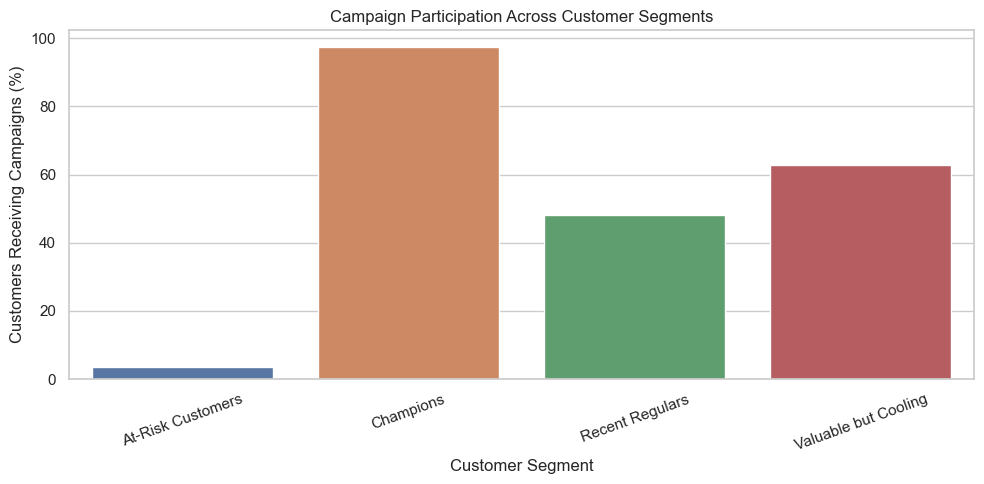

In [81]:
# Visualizing campaign participation
plt.figure(figsize=(10, 5))

sns.barplot(
    data=campaign_segment_summary.reset_index(),
    x="Segment",
    y="Participation_Pct",
    hue="Segment",
    legend=False
)

plt.title("Campaign Participation Across Customer Segments")
plt.xlabel("Customer Segment")
plt.ylabel("Customers Receiving Campaigns (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Coupon redemption analysis

In [82]:
# Inspect coupon redemption data

print("Total redemption records:", len(coupon_redempt))
print("Unique households:",
      coupon_redempt["household_key"].nunique())
print("Unique campaigns:",
      coupon_redempt["CAMPAIGN"].nunique())

print("\nDuplicate household-campaign-coupon records:",
      coupon_redempt.duplicated(
          subset=["household_key", "CAMPAIGN", "COUPON_UPC"]
      ).sum())

display(coupon_redempt.head())

Total redemption records: 2318
Unique households: 434
Unique campaigns: 30

Duplicate household-campaign-coupon records: 30


,household_key,DAY,COUPON_UPC,CAMPAIGN
0,1,421,10000085364,8
1,1,421,51700010076,8
2,1,427,54200000033,8
3,1,597,10000085476,18
4,1,597,54200029176,18


In [83]:
# Identify unique household-campaign combinations with redemption

redeemed_pairs = (
    coupon_redempt[
        ["household_key", "CAMPAIGN"]
    ]
    .drop_duplicates()
)

# Match redeemed campaigns with actual campaign assignments

matched_redemptions = campaign_household.merge(
    redeemed_pairs,
    on=["household_key", "CAMPAIGN"],
    how="left",
    indicator=True,
    validate="one_to_one"
)

matched_redemptions["Redeemed"] = (
    matched_redemptions["_merge"] == "both"
)

print("Exposed household-campaign pairs:",
      len(matched_redemptions))

print("Pairs with matched redemption:",
      matched_redemptions["Redeemed"].sum())

print("Redemption pairs not matching campaign exposure:",
      (matched_redemptions["_merge"] == "left_only").sum())

display(matched_redemptions.head())

Exposed household-campaign pairs: 7208
Pairs with matched redemption: 889
Redemption pairs not matching campaign exposure: 6319


,household_key,CAMPAIGN,DESCRIPTION,Segment,_merge,Redeemed
0,17,26,TypeA,Valuable but Cooling,left_only,False
1,27,26,TypeA,Champions,left_only,False
2,212,26,TypeA,Valuable but Cooling,left_only,False
3,208,26,TypeA,Champions,left_only,False
4,192,26,TypeA,Champions,left_only,False


In [84]:
# Calculating redemption rates by segment
redemption_summary = (
    matched_redemptions
    .groupby("Segment")
    .agg(
        Exposed_Household_Campaigns=("CAMPAIGN", "count"),
        Redeemed_Household_Campaigns=("Redeemed", "sum"),
        Exposed_Customers=("household_key", "nunique"),
        Redeeming_Customers=(
            "Redeemed",
            lambda x: matched_redemptions.loc[
                x.index, "household_key"
            ][x].nunique()
        )
    )
)

redemption_summary["Campaign_Redemption_Rate"] = (
    redemption_summary["Redeemed_Household_Campaigns"] /
    redemption_summary["Exposed_Household_Campaigns"] * 100
).round(2)

redemption_summary["Customer_Redemption_Rate"] = (
    redemption_summary["Redeeming_Customers"] /
    redemption_summary["Exposed_Customers"] * 100
).round(2)

display(redemption_summary.round(2))

,Exposed_Household_Campaigns,Redeemed_Household_Campaigns,Exposed_Customers,Redeeming_Customers,Campaign_Redemption_Rate,Customer_Redemption_Rate
Segment,,,,,,
At-Risk Customers,14,0,13,0,0.00,0.00
Champions,5418,769,906,350,14.19,38.63
Recent Regulars,652,43,307,35,6.60,11.40
Valuable but Cooling,1124,77,358,49,6.85,13.69


In [85]:
# Validating unmatched redemptions
# Identify unique household-campaign redemption pairs

redeemed_pairs = (
    coupon_redempt[
        ["household_key", "CAMPAIGN"]
    ]
    .drop_duplicates()
)

# Find redemptions without a corresponding campaign assignment

unmatched_redemption_pairs = redeemed_pairs.merge(
    campaign_household[
        ["household_key", "CAMPAIGN"]
    ],
    on=["household_key", "CAMPAIGN"],
    how="left",
    indicator=True
)

unmatched_redemption_pairs = (
    unmatched_redemption_pairs[
        unmatched_redemption_pairs["_merge"] == "left_only"
    ]
)

print("Unique redeemed household-campaign pairs:",
      len(redeemed_pairs))

print("Matched with campaign assignment:",
      len(redeemed_pairs) - len(unmatched_redemption_pairs))

print("Unmatched redemption pairs:",
      len(unmatched_redemption_pairs))

display(unmatched_redemption_pairs.head(10))

Unique redeemed household-campaign pairs: 889
Matched with campaign assignment: 889
Unmatched redemption pairs: 0


,household_key,CAMPAIGN,_merge


In [86]:
# Inspect repeated household-campaign-coupon combinations

duplicate_coupon_records = coupon_redempt[
    coupon_redempt.duplicated(
        subset=["household_key", "CAMPAIGN", "COUPON_UPC"],
        keep=False
    )
].sort_values(
    ["household_key", "CAMPAIGN", "COUPON_UPC", "DAY"]
)

print("Rows involved in repeated coupon combinations:",
      len(duplicate_coupon_records))

display(duplicate_coupon_records)

Rows involved in repeated coupon combinations: 60


,household_key,DAY,COUPON_UPC,CAMPAIGN
49,22,509,51440050055,13
50,22,526,51440050055,13
57,22,607,54850010033,18
61,22,640,54850010033,18
167,115,400,50813700076,5
169,115,407,50813700076,5
168,115,400,53600010082,5
170,115,407,53600010082,5
179,115,608,50008710076,19
181,115,625,50008710076,19


### Campaign-level performance

In [87]:
# Unique households assigned to each campaign

campaign_exposure = (
    campaign_household
    .groupby("CAMPAIGN")
    .agg(
        Exposed_Customers=("household_key", "nunique")
    )
    .reset_index()
)

display(campaign_exposure.head())

,CAMPAIGN,Exposed_Customers
0,1,13
1,2,48
2,3,12
3,4,81
4,5,166


In [88]:
# Count unique household-campaign redemption combinations

campaign_redemption = (
    redeemed_pairs
    .groupby("CAMPAIGN")
    .agg(
        Redeemed_Customers=("household_key", "nunique")
    )
    .reset_index()
)

display(campaign_redemption.head())

,CAMPAIGN,Redeemed_Customers
0,1,1
1,2,2
2,3,2
3,4,6
4,5,8


In [89]:
# Combine exposure and redemption data

campaign_performance = campaign_exposure.merge(
    campaign_redemption,
    on="CAMPAIGN",
    how="left"
)

campaign_performance["Redeemed_Customers"] = (
    campaign_performance["Redeemed_Customers"]
    .fillna(0)
    .astype(int)
)

# Calculate campaign redemption rate

campaign_performance["Redemption_Rate"] = (
    campaign_performance["Redeemed_Customers"] /
    campaign_performance["Exposed_Customers"] * 100
).round(2)

# Add campaign descriptions and dates

campaign_performance = campaign_performance.merge(
    campaign_desc[
        ["CAMPAIGN", "DESCRIPTION", "START_DAY", "END_DAY"]
    ],
    on="CAMPAIGN",
    how="left",
    validate="one_to_one"
)

campaign_performance["Duration"] = (
    campaign_performance["END_DAY"] -
    campaign_performance["START_DAY"] + 1
)

campaign_performance = (
    campaign_performance
    .sort_values("Redemption_Rate", ascending=False)
    .reset_index(drop=True)
)

display(campaign_performance)

,CAMPAIGN,Exposed_Customers,Redeemed_Customers,Redemption_Rate,DESCRIPTION,START_DAY,END_DAY,Duration
0,18,1133,214,18.89,TypeA,587,642,56
1,13,1077,196,18.20,TypeA,504,551,48
2,3,12,2,16.67,TypeC,356,412,57
3,8,1076,158,14.68,TypeA,412,460,49
4,25,187,24,12.83,TypeB,659,691,33
5,23,183,23,12.57,TypeB,646,684,39
6,15,17,2,11.76,TypeC,547,708,162
7,19,130,15,11.54,TypeB,603,635,33
8,9,176,20,11.36,TypeB,435,467,33
9,29,118,13,11.02,TypeB,281,334,54


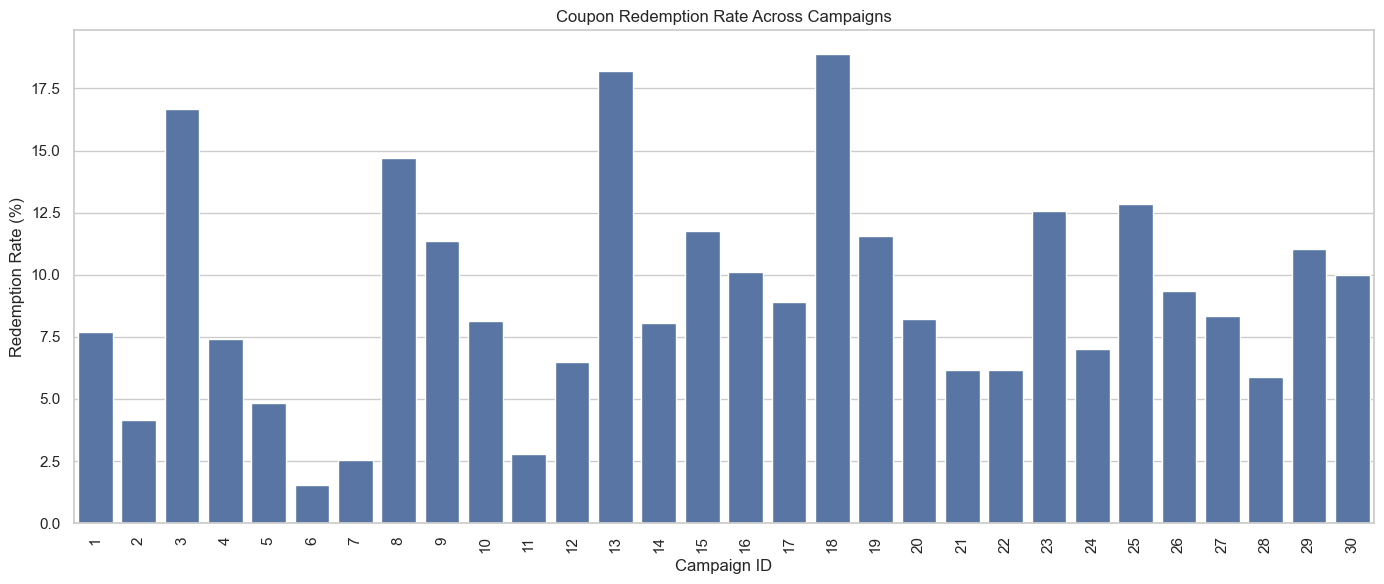

In [90]:
plt.figure(figsize=(14, 6))

sns.barplot(
    data=campaign_performance.sort_values(
        "Redemption_Rate",
        ascending=False
    ),
    x="CAMPAIGN",
    y="Redemption_Rate"
)

plt.title("Coupon Redemption Rate Across Campaigns")
plt.xlabel("Campaign ID")
plt.ylabel("Redemption Rate (%)")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [91]:
# Aggregate campaign performance by campaign type

campaign_type_summary = (
    campaign_performance
    .groupby("DESCRIPTION")
    .agg(
        Number_of_Campaigns=("CAMPAIGN", "nunique"),
        Total_Exposed=("Exposed_Customers", "sum"),
        Total_Redeemed=("Redeemed_Customers", "sum"),
        Average_Redemption_Rate=("Redemption_Rate", "mean"),
        Average_Duration=("Duration", "mean")
    )
)

# Calculate weighted redemption rate
campaign_type_summary["Weighted_Redemption_Rate"] = (
    campaign_type_summary["Total_Redeemed"] /
    campaign_type_summary["Total_Exposed"] * 100
)

display(campaign_type_summary.round(2))

,Number_of_Campaigns,Total_Exposed,Total_Redeemed,Average_Redemption_Rate,Average_Duration,Weighted_Redemption_Rate
DESCRIPTION,,,,,,
TypeA,5,3979,635,14.22,48.20,15.96
TypeB,19,2655,210,7.77,38.63,7.91
TypeC,6,574,44,9.09,75.50,7.67


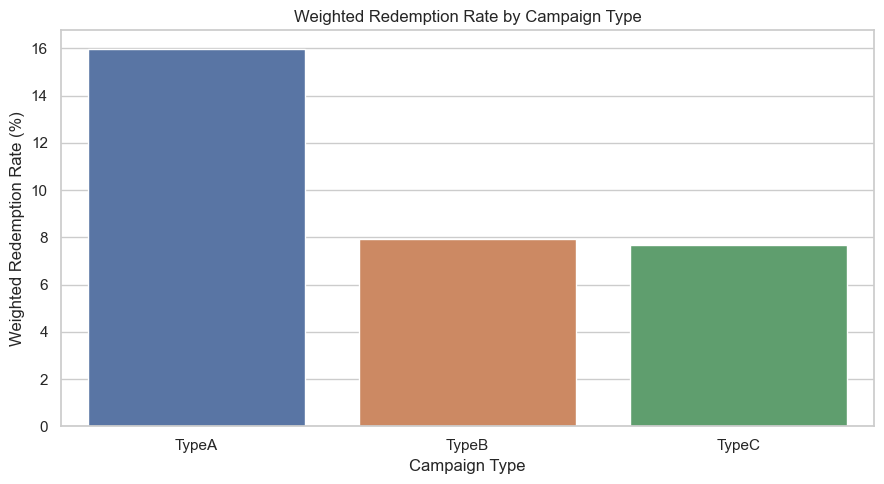

In [92]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=campaign_type_summary.reset_index(),
    x="DESCRIPTION",
    y="Weighted_Redemption_Rate",
    hue="DESCRIPTION",
    legend=False
)

plt.title("Weighted Redemption Rate by Campaign Type")
plt.xlabel("Campaign Type")
plt.ylabel("Weighted Redemption Rate (%)")

plt.tight_layout()
plt.show()

In [93]:
# Checking if campaign duration influence redemption
# Correlation analysis
from scipy.stats import spearmanr, pearsonr

# Spearman correlation
spearman_corr, spearman_p = spearmanr(
    campaign_performance["Duration"],
    campaign_performance["Redemption_Rate"]
)

# Pearson correlation
pearson_corr, pearson_p = pearsonr(
    campaign_performance["Duration"],
    campaign_performance["Redemption_Rate"]
)

print("Spearman Correlation:", round(spearman_corr, 4))
print("Spearman P-value:", spearman_p)

print("\nPearson Correlation:", round(pearson_corr, 4))
print("Pearson P-value:", pearson_p)

Spearman Correlation: 0.258
Spearman P-value: 0.1686403120998857

Pearson Correlation: 0.2193
Pearson P-value: 0.24429534706332912


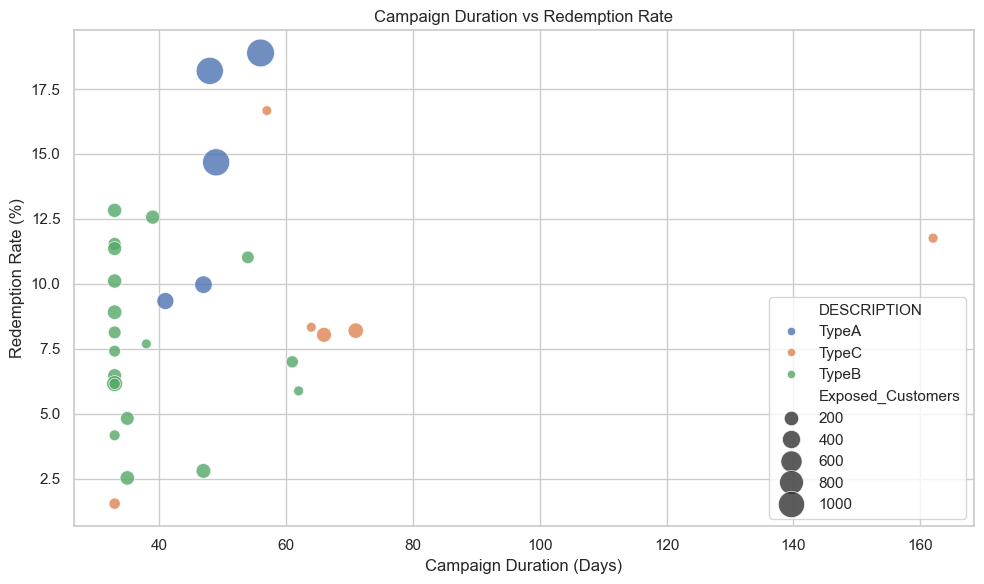

In [94]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=campaign_performance,
    x="Duration",
    y="Redemption_Rate",
    hue="DESCRIPTION",
    size="Exposed_Customers",
    sizes=(50, 400),
    alpha=0.8
)

plt.title("Campaign Duration vs Redemption Rate")
plt.xlabel("Campaign Duration (Days)")
plt.ylabel("Redemption Rate (%)")

plt.tight_layout()
plt.show()

In [95]:
display(
    campaign_performance[
        [
            "CAMPAIGN",
            "DESCRIPTION",
            "Duration",
            "Exposed_Customers",
            "Redeemed_Customers",
            "Redemption_Rate"
        ]
    ].sort_values(
        "Duration",
        ascending=False
    ).reset_index(drop=True)
)

,CAMPAIGN,DESCRIPTION,Duration,Exposed_Customers,Redeemed_Customers,Redemption_Rate
0,15,TypeC,162,17,2,11.76
1,20,TypeC,71,244,20,8.20
2,14,TypeC,66,224,18,8.04
3,27,TypeC,64,12,1,8.33
4,28,TypeB,62,17,1,5.88
5,24,TypeB,61,100,7,7.00
6,3,TypeC,57,12,2,16.67
7,18,TypeA,56,1133,214,18.89
8,29,TypeB,54,118,13,11.02
9,8,TypeA,49,1076,158,14.68


In [96]:
# Test whether campaign type is associated with redemption
# Create one record for each assigned household-campaign pair

campaign_type_analysis = matched_redemptions[
    ["household_key", "CAMPAIGN", "Redeemed"]
].merge(
    campaign_desc[
        ["CAMPAIGN", "DESCRIPTION", "START_DAY", "END_DAY"]
    ],
    on="CAMPAIGN",
    how="left",
    validate="many_to_one"
)

campaign_type_analysis["Duration"] = (
    campaign_type_analysis["END_DAY"]
    - campaign_type_analysis["START_DAY"] + 1
)

campaign_type_analysis["Redeemed"] = (
    campaign_type_analysis["Redeemed"].astype(int)
)

print("Total household-campaign observations:",
      len(campaign_type_analysis))

print("\nRedemption distribution:")
display(
    campaign_type_analysis["Redeemed"].value_counts()
)

print("\nCampaign type distribution:")
display(
    campaign_type_analysis.groupby("DESCRIPTION")
    .agg(
        Exposed=("Redeemed", "count"),
        Redeemed=("Redeemed", "sum"),
        Redemption_Rate=("Redeemed", "mean")
    )
)

Total household-campaign observations: 7208

Redemption distribution:


Redeemed
0    6319
1     889
Name: count, dtype: int64


Campaign type distribution:


,Exposed,Redeemed,Redemption_Rate
DESCRIPTION,,,
TypeA,3979,635,0.159588
TypeB,2655,210,0.079096
TypeC,574,44,0.076655


#### Chi-square test
The hypotheses:

$$H_0 : \text{Campaign type and redemption are independent}$$

$$H_1 : \text{Campaign type and redemption are associated}$$

In [97]:
# Compare redemption rates by campaign type
from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(
    campaign_type_analysis["DESCRIPTION"],
    campaign_type_analysis["Redeemed"]
)

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", round(chi2, 4))
print("Degrees of freedom:", dof)
print("P-value:", p_value)

display(contingency_table)

Chi-square statistic: 107.9902
Degrees of freedom: 2
P-value: 3.549996529166533e-24


Redeemed,0,1
DESCRIPTION,,
TypeA,3344,635
TypeB,2445,210
TypeC,530,44


In [98]:
# Logistic regression with household-clustered standard errors to estimate how redemption odds differ across campaign types while accounting for repeated observations from the same household
import statsmodels.api as sm
import statsmodels.formula.api as smf
import numpy as np

# Binary logistic regression
# TypeB is the reference category

model = smf.glm(
    formula="Redeemed ~ C(DESCRIPTION, Treatment(reference='TypeB'))",
    data=campaign_type_analysis,
    family=sm.families.Binomial()
)

# Cluster standard errors by household
result = model.fit(
    cov_type="cluster",
    cov_kwds={
        "groups": campaign_type_analysis["household_key"]
    }
)

print(result.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:               Redeemed   No. Observations:                 7208
Model:                            GLM   Df Residuals:                     7205
Model Family:                Binomial   Df Model:                            2
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2636.3
Date:                Mon, 23 Nov 2026   Deviance:                       5272.5
Time:                        18:33:57   Pearson chi2:                 7.21e+03
No. Iterations:                     5   Pseudo R-squ. (CS):            0.01543
Covariance Type:              cluster                                         
                                                            coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------

In [99]:
# Calculate odds ratios and confidence intervals

odds_ratios = pd.DataFrame({
    "Coefficient": result.params,
    "Odds_Ratio": np.exp(result.params),
    "P_Value": result.pvalues,
    "CI_Lower": np.exp(result.conf_int()[0]),
    "CI_Upper": np.exp(result.conf_int()[1])
})

display(odds_ratios.round(4))

,Coefficient,Odds_Ratio,P_Value,CI_Lower,CI_Upper
Intercept,-2.4547,0.0859,0.0000,0.0713,0.1035
"C(DESCRIPTION, Treatment(reference='TypeB'))[T.TypeA]",0.7934,2.2109,0.0000,1.8565,2.6329
"C(DESCRIPTION, Treatment(reference='TypeB'))[T.TypeC]",-0.0340,0.9666,0.8508,0.6783,1.3774


In [100]:
# Logistic regression controlling for campaign duration

model_duration = smf.glm(
    formula="""
        Redeemed ~
        C(DESCRIPTION, Treatment(reference='TypeB'))
        + Duration
    """,
    data=campaign_type_analysis,
    family=sm.families.Binomial()
)

result_duration = model_duration.fit(
    cov_type="cluster",
    cov_kwds={
        "groups": campaign_type_analysis["household_key"]
    }
)

print(result_duration.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:               Redeemed   No. Observations:                 7208
Model:                            GLM   Df Residuals:                     7204
Model Family:                Binomial   Df Model:                            3
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2632.9
Date:                Mon, 23 Nov 2026   Deviance:                       5265.8
Time:                        18:33:58   Pearson chi2:                 7.22e+03
No. Iterations:                     5   Pseudo R-squ. (CS):            0.01635
Covariance Type:              cluster                                         
                                                            coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------

In [101]:
duration_odds_ratios = pd.DataFrame({
    "Coefficient": result_duration.params,
    "Odds_Ratio": np.exp(result_duration.params),
    "P_Value": result_duration.pvalues,
    "CI_Lower": np.exp(result_duration.conf_int()[0]),
    "CI_Upper": np.exp(result_duration.conf_int()[1])
})

display(duration_odds_ratios.round(4))

,Coefficient,Odds_Ratio,P_Value,CI_Lower,CI_Upper
Intercept,-2.9040,0.0548,0.0000,0.0385,0.0781
"C(DESCRIPTION, Treatment(reference='TypeB'))[T.TypeA]",0.6413,1.8989,0.0000,1.5693,2.2976
"C(DESCRIPTION, Treatment(reference='TypeB'))[T.TypeC]",-0.4197,0.6572,0.0590,0.4251,1.0161
Duration,0.0120,1.0121,0.0014,1.0047,1.0196


In [102]:
# Comparing two Logistic Regression models
from scipy.stats import chi2

# Likelihood ratio test

lr_stat = 2 * (
    result_duration.llf - result.llf
)

df_diff = (
    result_duration.df_model - result.df_model
)

lr_p_value = chi2.sf(lr_stat, df_diff)

print("Likelihood Ratio Test")
print("---------------------")
print("LR Statistic:", round(lr_stat, 4))
print("Degrees of Freedom:", int(df_diff))
print("P-value:", lr_p_value)

print("\nModel comparison")
print("----------------")
print("Model 1 Log-Likelihood:", round(result.llf, 4))
print("Model 2 Log-Likelihood:", round(result_duration.llf, 4))
print("Model 1 Pseudo R²:", round(result.pseudo_rsquared(), 5))
print("Model 2 Pseudo R²:", round(result_duration.pseudo_rsquared(), 5))

Likelihood Ratio Test
---------------------
LR Statistic: 6.7005
Degrees of Freedom: 1
P-value: 0.009638794255553971

Model comparison
----------------
Model 1 Log-Likelihood: -2636.2608
Model 2 Log-Likelihood: -2632.9106
Model 1 Pseudo R²: 0.01543
Model 2 Pseudo R²: 0.01635


### Customer segment × campaign type analysis

In [103]:
segment_campaign_analysis = (
    campaign_type_analysis
    .merge(
        customer_segments[["household_key", "Segment"]],
        on="household_key",
        how="left",
        validate="many_to_one"
    )
)

print("Total observations:",
      len(segment_campaign_analysis))

display(
    segment_campaign_analysis.groupby(
        ["Segment", "DESCRIPTION"]
    ).agg(
        Exposed=("Redeemed", "count"),
        Redeemed=("Redeemed", "sum"),
        Redemption_Rate=("Redeemed", "mean")
    ).round(4)
)

Total observations: 7208


Exposed  Redeemed  Redemption_Rate
Segment              DESCRIPTION                                    
At-Risk Customers    TypeA             11         0           0.0000
                     TypeB              3         0           0.0000
Champions            TypeA           2723       537           0.1972
                     TypeB           2205       191           0.0866
                     TypeC            490        41           0.0837
Recent Regulars      TypeA            478        39           0.0816
                     TypeB            154         4           0.0260
                     TypeC             20         0           0.0000
Valuable but Cooling TypeA            767        59           0.0769
                     TypeB            293        15           0.0512
                     TypeC             64         3           0.0469

In [104]:
segment_type_summary = (
    segment_campaign_analysis
    .groupby(["Segment", "DESCRIPTION"])
    .agg(
        Exposed=("Redeemed", "count"),
        Redeemed=("Redeemed", "sum")
    )
    .reset_index()
)

segment_type_summary["Redemption_Rate"] = (
    segment_type_summary["Redeemed"] /
    segment_type_summary["Exposed"] * 100
)

display(
    segment_type_summary.sort_values(
        ["Segment", "Redemption_Rate"],
        ascending=[True, False]
    ).round(2)
)

,Segment,DESCRIPTION,Exposed,Redeemed,Redemption_Rate
0,At-Risk Customers,TypeA,11,0,0.00
1,At-Risk Customers,TypeB,3,0,0.00
2,Champions,TypeA,2723,537,19.72
3,Champions,TypeB,2205,191,8.66
4,Champions,TypeC,490,41,8.37
5,Recent Regulars,TypeA,478,39,8.16
6,Recent Regulars,TypeB,154,4,2.60
7,Recent Regulars,TypeC,20,0,0.00
8,Valuable but Cooling,TypeA,767,59,7.69
9,Valuable but Cooling,TypeB,293,15,5.12


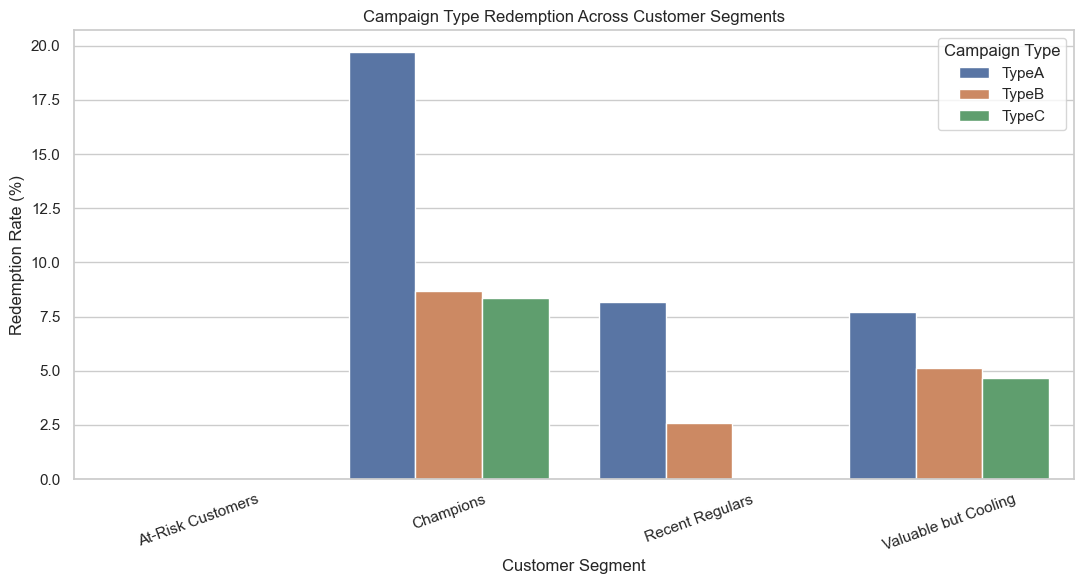

In [105]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=segment_type_summary,
    x="Segment",
    y="Redemption_Rate",
    hue="DESCRIPTION"
)

plt.title("Campaign Type Redemption Across Customer Segments")
plt.xlabel("Customer Segment")
plt.ylabel("Redemption Rate (%)")
plt.xticks(rotation=20)
plt.legend(title="Campaign Type")

plt.tight_layout()
plt.show()

In [106]:
# Pivot campaign redemption rates

rate_comparison = segment_type_summary.pivot(
    index="Segment",
    columns="DESCRIPTION",
    values="Redemption_Rate"
)

# Calculate percentage-point differences

rate_comparison["TypeA_vs_TypeB_Difference"] = (
    rate_comparison["TypeA"] -
    rate_comparison["TypeB"]
)

rate_comparison["TypeA_vs_TypeC_Difference"] = (
    rate_comparison["TypeA"] -
    rate_comparison["TypeC"]
)

# Calculate relative lift (%)
# Avoid division by zero

rate_comparison["TypeA_vs_TypeB_Lift"] = (
    rate_comparison["TypeA"] /
    rate_comparison["TypeB"] - 1
) * 100

rate_comparison["TypeA_vs_TypeC_Lift"] = (
    rate_comparison["TypeA"] /
    rate_comparison["TypeC"] - 1
) * 100

display(rate_comparison.round(2))

DESCRIPTION,TypeA,TypeB,TypeC,TypeA_vs_TypeB_Difference,TypeA_vs_TypeC_Difference,TypeA_vs_TypeB_Lift,TypeA_vs_TypeC_Lift
Segment,,,,,,,
At-Risk Customers,0.00,0.00,NaN,0.00,NaN,NaN,NaN
Champions,19.72,8.66,8.37,11.06,11.35,127.67,135.69
Recent Regulars,8.16,2.60,0.00,5.56,8.16,214.12,inf
Valuable but Cooling,7.69,5.12,4.69,2.57,3.00,50.26,64.10


In [107]:
customer_segments.head()

,household_key,Recency,Frequency,Monetary,Cluster,Segment
0,1,6,85,4249.60,0,Champions
1,2,44,45,1945.34,1,Valuable but Cooling
2,3,9,47,2592.02,3,Recent Regulars
3,4,85,30,1197.61,1,Valuable but Cooling
4,5,9,40,779.06,3,Recent Regulars


In [110]:
# Saving images
#import json
#import base64
#import csv
#from pathlib import Path

# Locate the latest project notebook
#notebook_files = sorted(
#    Path.cwd().glob("01_data_understanding*.ipynb"),
#    key=lambda p: p.stat().st_mtime,
#    reverse=True
#)

#if not notebook_files:
#    raise FileNotFoundError(
#        "Project notebook not found in the current directory."
#    )

#notebook_path = notebook_files[0]

#print("Reading notebook:", notebook_path.name)

# Create images directory
#images_dir = Path("../images")
#images_dir.mkdir(parents=True, exist_ok=True)

# Read notebook
#with open(notebook_path, "r", encoding="utf-8") as f:
#    notebook = json.load(f)

# Extract all PNG images
#exported_images = []
#image_count = 0

#for cell_number, cell in enumerate(
#    notebook.get("cells", []), start=1
#):
#    for output_number, output in enumerate(
#        cell.get("outputs", []), start=1
#    ):

#        image_data = output.get("data", {}).get("image/png")

#        if image_data is not None:

            # Handle base64 image data
#            if isinstance(image_data, list):
#                image_data = "".join(image_data)

#            image_bytes = base64.b64decode(image_data)

#            image_count += 1

#            filename = (
#                f"chart_{image_count:02d}_cell_{cell_number:03d}.png"
#            )

#            image_path = images_dir / filename

#            with open(image_path, "wb") as img:
#                img.write(image_bytes)

#            exported_images.append([
#                filename,
#                cell_number,
#                output_number
#            ])

# Create an export manifest
#manifest_path = images_dir / "image_manifest.csv"

#with open(manifest_path, "w", newline="", encoding="utf-8") as f:
#    writer = csv.writer(f)
#    writer.writerow([
#        "Image_Filename",
#        "Notebook_Cell",
#        "Output_Number"
#    ])
#    writer.writerows(exported_images)

#print("\nExport completed!")
#print("Total images exported:", image_count)
#print("Images directory:", images_dir.resolve())

#for filename, cell, output in exported_images:
#    print(filename)